# E99 · Which beacon to ping: range-only localisation on real radio logs

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: the CMU **"Plaza" ultra-wideband radio logs** of Djugash, Hamner & Roth (2009, *Journal of Field Robotics*), via the EPFL Infoscience mirror: two drives across a campus plaza with four radio beacons, each with a time-of-flight **range log** (3,529 and 1,816 ranges), **wheel odometry** and a **GPS/INS track** (about 2 cm) to score against. Plaza 1 (32 minutes) calibrates; Plaza 2 (7 minutes) is replayed |
| **You will learn** | Calibrating a **range sensor** against ground truth in PyMC: a constant bias that fails its posterior predictive check, a **scale error** that fixes it, and a **non-line-of-sight mixture** (ex-Gaussian tail) that the data do not need · checking the calibration on a **held-out run** with PIT · an odometry model and a **gyro drift** that the calibration run could not show · a **particle filter** for **ring-shaped, multimodal** beliefs, and why a Kalman filter cannot hold them · **global localisation** from an unknown start, and a filter that is **sure and wrong** until **sensor resetting** rescues it · choosing which beacon to ping by **expected information gain** (mutual information, nested Monte Carlo) against round-robin, random, nearest-beacon and **predicted-range spread**, by **counterfactual replay** of a real log · a **beacon-SLAM** extension in which one beacon's position is unknown |

## The setting

Indoors, under trees or between tall buildings, GPS is weak or absent, and a robot has to find
itself some other way. One cheap way is a handful of **radio beacons** at known places. An
ultra-wideband (UWB) radio can time how long a pulse takes to reach a beacon and come back, which
gives the **range** - the distance to that beacon - to within tens of centimetres, but nothing about
the direction. One range puts the robot somewhere on a circle around the beacon. Two circles cross
in two points, mirror images of each other across the line joining the beacons. A third beacon, or
the robot's own motion seen through its wheel odometry, breaks the tie. Kantor & Singh (2002) and
Kurth, Kantor & Singh (2003) built range-only localisation on exactly this idea, and Djugash, Hamner
& Roth (2009) released five data sets with ground truth so that others could test their methods.
We use two of them.

Range-only data make the belief about where the robot is a strange shape: a ring, then two blobs,
then sometimes a string of clusters. A Kalman filter (E13) summarises a belief by one mean and one
covariance, so it cannot hold a ring or two blobs; it linearises around the wrong point and commits
to one blob, right or wrong. A **particle filter** (Gordon, Salmond & Smith 1993; Monte Carlo
localisation, Dellaert et al. 1999) carries thousands of weighted guesses and can hold any shape.

The question of this notebook comes from a constraint that real radio networks have. Beacons share
a channel and run on batteries, so a robot gets a time slot in which it may **ping one beacon**. If
it can ask only one beacon every two seconds, **which one should it ask?** The obvious answers are
to go round them in turn, or to ask the nearest one, because its signal is strongest. The Bayesian
answer is to ask the beacon whose reply is expected to teach the most about where the robot is: the
**expected information gain** of an experiment (Lindley 1956), which is the mutual information
between the reply and the robot's position. Fox, Burgard & Thrun (1998) used it to decide where a
robot should look; Zhao, Shin & Reich (2002) to decide which sensor in a network to query.

We test the idea on a real log rather than a simulator. Every range the agent may reveal was
actually measured. In each two-second window the agent picks one beacon from those that answered
in that window, sees only that range, and the rest of the window's ranges are thrown away. The belief
changes, and so does the next choice. One limit is built in: **we choose what to reveal, not where to
drive.** The robot's path is the one in the log, whatever the agent believes. The GPS track and the
surveyed beacon positions are used only to calibrate on the first run and to score on the second.

| part | question | tool |
|---|---|---|
| 1 | What is in the logs? | two drives, four beacons, odometry against GPS |
| 2 | How wrong are the radios, and how? | PyMC: offset, scale and NLOS-mixture models; PPC, LOO, a held-out run |
| 3 | How wrong is the odometry? | a PyMC displacement model; a gyro drift found on the second run |
| 4 | How do we track a ring-shaped belief? | a particle filter; global localisation; sensor resetting |
| 5 | Which beacon should the robot ping? | expected information gain against four simple rules, by replay |
| 6 | What does fusion buy over a whole run? | odometry alone against odometry plus chosen pings |
| 7 | What if one beacon was never surveyed? | beacon SLAM with per-particle beacon positions |
| 8 | What should the robot run? | the decision |

In [1]:
import os

for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(name, "1")

import logging
import sys
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from scipy.cluster.vq import kmeans2
from scipy.special import ndtr

from pymc_challenges import data

sys.modules.pop("jax", None)   # ArviZ's lazy JAX stub would import all of JAX for nothing (see E89)

RANDOM_SEED = 99
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning, module="arviz")
pd.set_option("display.width", 150)
T_START = time.time()

BLUE, ORANGE, AQUA, PURPLE, RED, GREY, INK = (
    "#2a78d6", "#eb6834", "#1baf7a", "#8c5ac8", "#c8384e", "#8a8a86", "#222222")
BEACON_IDS = [0, 1, 5, 6]
BCOL = {0: BLUE, 1: ORANGE, 5: AQUA, 6: PURPLE}
print(f"PyMC {pm.__version__}, ArviZ {az.__version__}")

PyMC 6.3.2, ArviZ 1.3.0


## 1 · Two drives across a plaza

Each run has four files' worth of arrays: the GPS/INS ground truth (time, position, heading), the
wheel odometry (distance travelled and heading change per step) and its integrated path, the
surveyed positions of the four beacons (ids 0, 1, 5 and 6 in both runs, but placed differently), and
the range log (time, beacon id, range in metres). The data set's release went through an
Infoscience record whose download now sits behind a captcha, so the two Plaza runs are cached in
the repository as one small file, values unchanged.

e99_plaza_uwb: npz, two runs of a robot driving on a campus plaza with four ultra-wideband (UWB) radio beacons, k = 1 (1,932 s) and 2 (410 s): p{k}_gt (time s, x m, y m, heading rad; GPS/INS ground truth, ~2 cm), p{k}_dr (time, distance travelled m, heading change rad, per odometry step), p{k}_drp (time, x, y, heading of the integrated dead-reckoned path), p{k}_tl (beacon id, x, y: surveyed beacon positions; ids 0, 1, 5, 6 in both runs, placed differently), p{k}_td (time, robot id, beacon id, range m: the UWB time-of-flight range log; 3,529 and 1,816 ranges).
  source: Djugash, Hamner & Roth (2009), 'Navigating with ranging radios: Five data sets with ground truth', Journal of Field Robotics 26(9):689-707; mirror of the original CMU release at EPFL Infoscience, record 283435 (RangeOnlyDataset.zip, 3,616,837 bytes, md5 e8e8fb60c96f0c3ab6f9e47d87418df3; licence field 'n/a': cite the paper). No licence is stated; redistributing this small extract relies on the authors having released the 

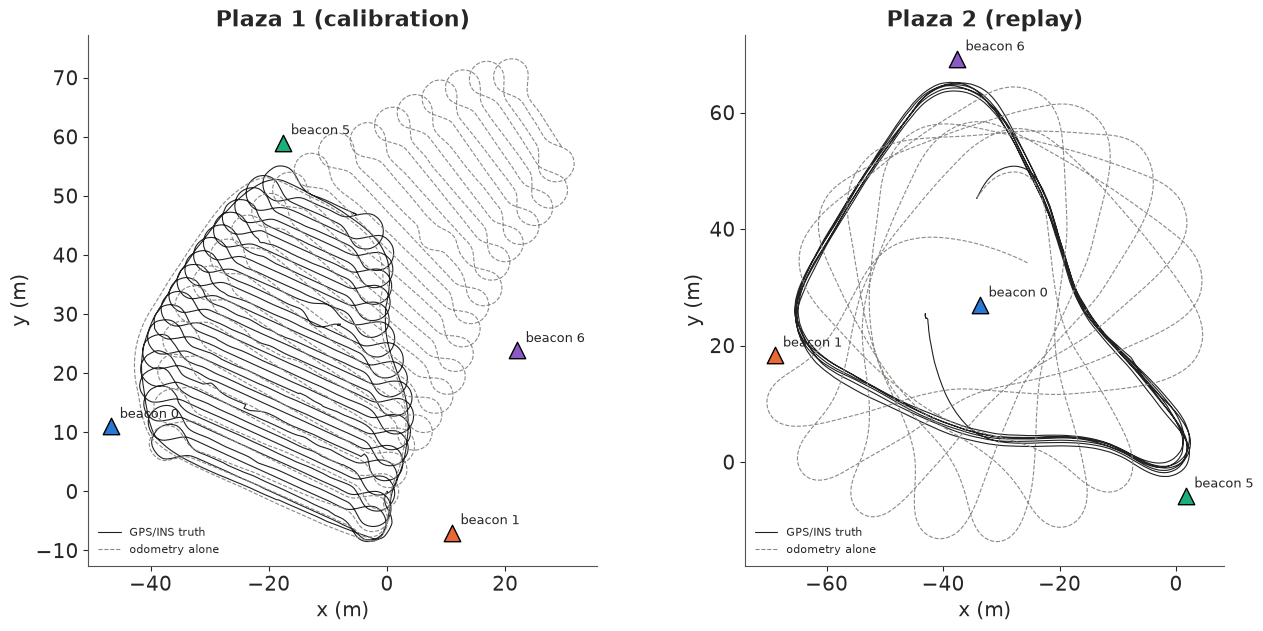

In [2]:
data.describe("e99_plaza_uwb")
Z = np.load(data.path("e99_plaza_uwb"))


def load_run(k):
    gt, dr, drp, tl, td = (Z[f"p{k}_{s}"] for s in ("gt", "dr", "drp", "tl", "td"))
    run = dict(gt=gt, dr=dr, drp=drp, td=td)
    run["bxy"] = np.array([tl[tl[:, 0] == b, 1:3][0] for b in BEACON_IDS])   # rows in BEACON_IDS order
    run["j"] = np.array([BEACON_IDS.index(int(b)) for b in td[:, 2]])         # beacon index of each range
    run["xy_at"] = lambda t: np.c_[np.interp(t, gt[:, 0], gt[:, 1]), np.interp(t, gt[:, 0], gt[:, 2])]
    xy = run["xy_at"](td[:, 0])
    run["d"] = np.hypot(*(xy - run["bxy"][run["j"]]).T)                     # true distance at each range
    run["r"] = td[:, 3]
    return run


P1, P2 = load_run(1), load_run(2)
for name, R in (("Plaza 1", P1), ("Plaza 2", P2)):
    gt = R["gt"]
    dur = gt[-1, 0] - gt[0, 0]
    path = np.hypot(*np.diff(gt[:, 1:3], axis=0).T).sum()
    dr_end = np.hypot(*(R["drp"][-1, 1:3] - gt[-1, 1:3]))
    print(f"{name}: {dur:.0f} s, {path:,.0f} m driven ({path / dur:.1f} m/s), {len(R['r']):,} ranges "
          f"({len(R['r']) / dur:.1f} per s), odometry {1 / np.median(np.diff(R['dr'][:, 0])):.0f} Hz; "
          f"dead reckoning ends {dr_end:.0f} m from the truth")

fig, axs = plt.subplots(1, 2, figsize=(13, 6.2))
for ax, (name, R) in zip(axs, (("Plaza 1 (calibration)", P1), ("Plaza 2 (replay)", P2))):
    ax.plot(R["gt"][:, 1], R["gt"][:, 2], color=INK, lw=0.8, label="GPS/INS truth")
    ax.plot(R["drp"][:, 1], R["drp"][:, 2], color=GREY, lw=0.8, ls="--", label="odometry alone")
    for b, (bx, by) in zip(BEACON_IDS, R["bxy"]):
        ax.scatter(bx, by, s=140, marker="^", color=BCOL[b], edgecolor="k", zorder=5)
        ax.annotate(f"beacon {b}", (bx, by), xytext=(6, 6), textcoords="offset points", fontsize=9)
    ax.set(title=name, xlabel="x (m)", ylabel="y (m)", aspect="equal")
    ax.legend(loc="lower left", fontsize=8);

The two runs are different in kind. Plaza 1 is a robot mowing the plaza in a lawnmower pattern at
walking pace for 32 minutes (1.9 km at 1.0 m/s), with a range every half second or so. Plaza 2 is
seven minutes of fast loops (1.4 km at 3.3 m/s) with more than four ranges a second. Odometry on its
own is not a position: Plaza 1's dead-reckoned path slides off as a sheared copy of the true pattern
and ends 37 m away, and Plaza 2's turns the one loop into a rosette as its heading creeps round, so
that it is anywhere from a few metres to tens of metres off. The robot in Plaza 2 also stands still
for its first twenty seconds or so (the short stub inside the loop), which will matter later: a
stationary robot's heading cannot be learned from ranges.

We calibrate on Plaza 1 and replay Plaza 2. Plaza 1 is the better teacher - longer, with the robot
at every distance from every beacon - and Plaza 2 is the better test of choice: in almost every
two-second window all four beacons answered, so the agent always has a real choice to make.

## 2 · Calibrating the radios against GPS (Plaza 1)

With the GPS position $p(t)$ and the surveyed beacon position $b_j$, the true distance at the time
of each range is $d_i = \lVert p(t_i) - b_{j(i)} \rVert$, interpolating the 5 Hz GPS track to the
range's timestamp. A range sensor's error model says how the measured range $r_i$ relates to $d_i$.
The first idea, and the one the data seem to suggest, is a constant **bias** per beacon plus noise:

$$r_i = d_i + \beta_{j(i)} + \varepsilon_i, \qquad \varepsilon_i \sim \mathcal N(0, \sigma^2).$$

The priors are wide (offsets $\mathcal N(0, 5^2)$ m, $\sigma \sim$ HalfNormal(2) m), because before
looking we only know that UWB offsets of metres are common.

In [3]:
r1, d1, j1 = P1["r"], P1["d"], P1["j"]
res1 = r1 - d1
print(f"Plaza 1: range minus true distance, median {np.median(res1):+.2f} m, "
      f"quartiles {np.percentile(res1, 25):+.2f} to {np.percentile(res1, 75):+.2f} m")
coords = {"beacon": [str(b) for b in BEACON_IDS], "obs": np.arange(len(r1))}
LOO = {}


def fit(model, name, predictive=True):
    """Sample; keep the LOO result (not the pointwise log-likelihood) and a thinned posterior predictive."""
    with model:
        idata = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
        pm.compute_log_likelihood(idata, progressbar=False)
        LOO[name] = az.loo(idata, pointwise=True)
        LOO[name].log_weights = None
        del idata["log_likelihood"]
        pp = (pm.sample_posterior_predictive(idata.isel(draw=slice(None, None, 10)), random_seed=RANDOM_SEED,
                                             progressbar=False) if predictive else None)
    return idata, pp


with pm.Model(coords=coords) as m_offset:
    beta = pm.Normal("beta", 0.0, 5.0, dims="beacon")
    sigma = pm.HalfNormal("sigma", 2.0)
    pm.Normal("r", d1 + beta[j1], sigma, observed=r1, dims="obs")
idata_offset, pp_offset = fit(m_offset, "offset")
print(az.summary(idata_offset, var_names=["beta", "sigma"], round_to=3))

Plaza 1: range minus true distance, median +2.84 m, quartiles +1.97 to +3.61 m


          mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
beta[0]  2.600  0.038     2.540     2.661  6221.196  3421.819  1.001      0.000    0.001
beta[1]  2.904  0.039     2.841     2.965  5683.680  2968.604  1.001      0.001    0.001
beta[5]  2.791  0.040     2.729     2.855  6987.185  3160.098  1.003      0.000    0.001
beta[6]  2.880  0.038     2.819     2.942  6094.445  3300.584  1.001      0.000    0.001
sigma    1.141  0.013     1.120     1.162  7140.388  3491.238  1.000      0.000    0.000


bins outside the 94% replicated band: 12 of 13


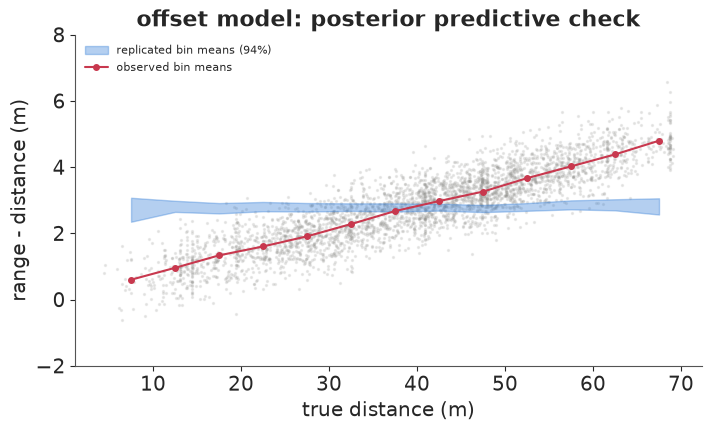

In [4]:
def binned_residual_check(pp, ax, title):
    """Observed vs replicated mean residual (range minus true distance) in distance bins."""
    edges = np.arange(0, 75, 5.0)
    k = np.digitize(d1, edges) - 1
    keep = np.bincount(k, minlength=len(edges)) >= 20
    centres = edges[:-1] + 2.5
    obs = np.array([res1[k == i].mean() if keep[i] else np.nan for i in range(len(centres))])
    rep = pp.posterior_predictive["r"].values.reshape(-1, len(d1)) - d1
    rep_b = np.array([[row[k == i].mean() if keep[i] else np.nan for i in range(len(centres))] for row in rep])
    lo, hi = np.full(len(centres), np.nan), np.full(len(centres), np.nan)
    lo[keep[:len(centres)]], hi[keep[:len(centres)]] = np.quantile(rep_b[:, keep[:len(centres)]], [0.03, 0.97], axis=0)
    ax.scatter(d1, res1, s=2, alpha=0.15, color=GREY, rasterized=True)
    ax.fill_between(centres, lo, hi, color=BLUE, alpha=0.35, label="replicated bin means (94%)")
    ax.plot(centres, obs, "o-", color=RED, ms=4, label="observed bin means")
    ax.set(xlabel="true distance (m)", ylabel="range - distance (m)", title=title, ylim=(-2, 8))
    ax.legend(fontsize=8, loc="upper left")
    return obs, lo, hi


fig, ax = plt.subplots(figsize=(7, 4.2))
obs, lo, hi = binned_residual_check(pp_offset, ax, "offset model: posterior predictive check")
outside = np.sum((obs < lo) | (obs > hi))
print(f"bins outside the 94% replicated band: {outside} of {np.sum(~np.isnan(obs))}");

**Failure 1: a bias that is not a bias.** The ranges are long by a median of 2.8 m, and the offset
model duly finds offsets of 2.6-2.9 m for the four beacons, with a noise sd of 1.1 m. The sampler
is happy (r_hat 1.00, thousands of effective draws), and a summary table would look fine. The
posterior predictive check does not. We bin the ranges by true distance and compare each bin's mean
error with the same statistic in replicated data: 12 of the 13 bins fall outside the 94% band. The
error is not constant; it grows in a straight line, from about 0.6 m at 8 m to 4.8 m at 68 m. A
"bias" of 2.8 m was the error at the average distance.

A line through the origin is a **scale error**: the radios read every distance about 7% long. That
is what a wrong speed-of-light constant or a clock running at the wrong rate would do, and it is
also what a scale difference between the surveyed beacon coordinates and the GPS frame would do. The
log cannot tell these apart, and for navigating in the surveyed frame it does not need to. So the
second model has a shared fractional scale error $\kappa$ and small per-beacon offsets:

$$r_i = (1 + \kappa)\, d_i + \beta_{j(i)} + \varepsilon_i, \qquad \kappa \sim \mathcal N(0, 0.1^2),
\quad \beta_j \sim \mathcal N(0, 1).$$

          mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
kappa    0.069  0.001     0.068     0.070   829.307  1244.857  1.006      0.000    0.000
beta[0]  0.022  0.029    -0.024     0.070  1079.246  1712.809  1.003      0.001    0.000
beta[1]  0.058  0.031     0.007     0.107  1044.685  1495.350  1.003      0.001    0.001
beta[5]  0.041  0.030    -0.007     0.089  1075.382  1514.799  1.002      0.001    0.001
beta[6]  0.012  0.031    -0.036     0.063  1007.213  1583.732  1.004      0.001    0.001
sigma    0.541  0.006     0.531     0.551  3301.566  2586.615  1.001      0.000    0.000
bins outside the 94% replicated band: 1 of 13


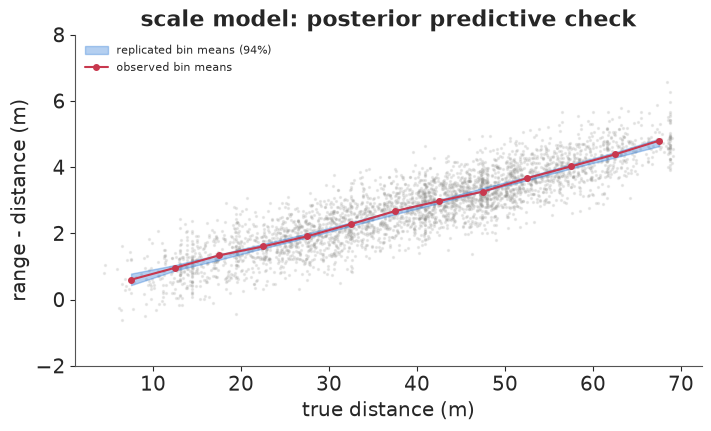

In [5]:
with pm.Model(coords=coords) as m_scale:
    kappa = pm.Normal("kappa", 0.0, 0.1)                     # fractional scale error
    beta = pm.Normal("beta", 0.0, 1.0, dims="beacon")         # per-beacon offset (m)
    sigma = pm.HalfNormal("sigma", 1.0)
    pm.Normal("r", (1 + kappa) * d1 + beta[j1], sigma, observed=r1, dims="obs")
idata_scale, pp_scale = fit(m_scale, "scale")
print(az.summary(idata_scale, var_names=["kappa", "beta", "sigma"], round_to=3))
fig, ax = plt.subplots(figsize=(7, 4.2))
obs, lo, hi = binned_residual_check(pp_scale, ax, "scale model: posterior predictive check")
print(f"bins outside the 94% replicated band: {np.sum((obs < lo) | (obs > hi))} of {np.sum(~np.isnan(obs))}");

The scale model puts $\kappa$ at 0.069 (6.9%, with a posterior sd of 0.1 percentage points), the four
offsets within 6 cm of zero, and the noise sd at 0.54 m. The same check now passes: the replicated
band follows the observed bin means from 8 m to 68 m, and one bin of 13 is just outside it, about
what 94% bands give by chance. One shared number explains what looked like four biases.

Radio ranging has a second, better-known error. When the direct path is blocked - by a person, a
tree, a lamp post - the first pulse to arrive is a reflection, and the range is **too long**, never
too short. This **non-line-of-sight (NLOS)** error gives range residuals a positive tail, and the
usual model is a mixture: most ranges are Gaussian around the true distance, a share $\pi$ carry an
extra delay. An exponential delay added to a Gaussian is an **ex-Gaussian** distribution, so

$$r_i \sim (1 - \pi)\,\mathcal N(\mu_i, \sigma^2) + \pi\,\text{ExGaussian}(\mu_i, \sigma, \tau),
\qquad \mu_i = (1 + \kappa) d_i + \beta_{j(i)},$$

where $\tau$ is the mean extra delay. The priors say NLOS ranges are a minority ($\pi \sim$
Beta(1, 9), mean 0.1) with delays of a metre or two ($\tau \sim$ Gamma(2, 1), mean 2 m). Before
fitting we look at what these priors imply for the data.

prior: scale error kappa 94% in [-0.202  0.185], NLOS share 94% in [0.003 0.267], mean extra delay 94% in [0.33 5.23] m
prior predictive range - distance beyond 50 m: 94% in [-12.   11.4] m; observed: [2.9 5.3] m


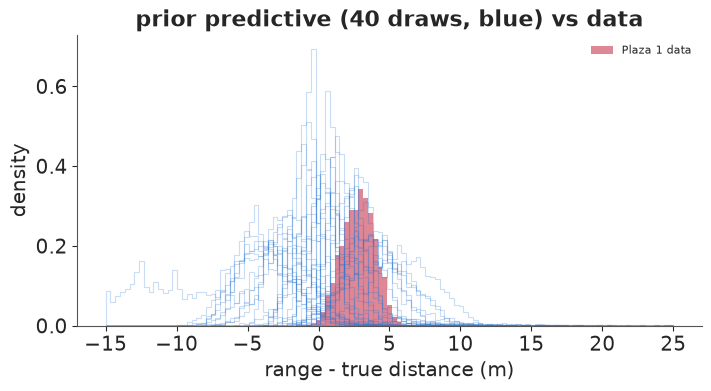

In [6]:
with pm.Model(coords=coords) as m_nlos:
    kappa = pm.Normal("kappa", 0.0, 0.1)
    beta = pm.Normal("beta", 0.0, 1.0, dims="beacon")
    sigma = pm.HalfNormal("sigma", 1.0)
    pi_nlos = pm.Beta("pi_nlos", 1.0, 9.0)                    # share of ranges with a delayed path
    tau = pm.Gamma("tau", 2.0, 1.0)                           # mean extra delay of those ranges (m)
    mu = (1 + kappa) * d1 + beta[j1]
    pm.Mixture("r", w=pt.stack([1 - pi_nlos, pi_nlos]),
               comp_dists=[pm.Normal.dist(mu, sigma), pm.ExGaussian.dist(mu=mu, sigma=sigma, nu=tau)],
               observed=r1, dims="obs")
    prior_nlos = pm.sample_prior_predictive(draws=500, random_seed=RANDOM_SEED)

pr = prior_nlos.prior
pp_res = prior_nlos.prior_predictive["r"].values[0] - d1          # (draw, obs)
far = d1 > 50
print(f"prior: scale error kappa 94% in {np.quantile(pr['kappa'], [0.03, 0.97]).round(3)}, "
      f"NLOS share 94% in {np.quantile(pr['pi_nlos'], [0.03, 0.97]).round(3)}, "
      f"mean extra delay 94% in {np.quantile(pr['tau'], [0.03, 0.97]).round(2)} m")
print(f"prior predictive range - distance beyond 50 m: 94% in {np.quantile(pp_res[:, far], [0.03, 0.97]).round(1)} m; "
      f"observed: {np.quantile(res1[far], [0.03, 0.97]).round(1)} m")
fig, ax = plt.subplots(figsize=(7, 3.8))
for row in pp_res[:40]:
    ax.hist(row, bins=np.linspace(-15, 25, 120), histtype="step", density=True, color=BLUE, alpha=0.25, lw=0.8)
ax.hist(res1, bins=np.linspace(-15, 25, 120), density=True, color=RED, alpha=0.6, label="Plaza 1 data")
ax.set(xlabel="range - true distance (m)", ylabel="density", title="prior predictive (40 draws, blue) vs data")
ax.legend(fontsize=8);

The prior allows scale errors of up to about 20% either way, NLOS shares from almost none to a
quarter, and mean delays from 0.3 to 5 m. For ranges beyond 50 m, that puts range minus distance
anywhere from -12 to +11 m (94% of prior draws), against an observed 2.9 to 5.3 m. The prior
predictive curves (blue) are wide, some with long right tails, but none absurd, and the data sit
comfortably inside what they allow. That is the job of a prior here: rule out nonsense, leave the
rest to 3,529 ranges.

In [7]:
idata_nlos, _ = fit(m_nlos, "scale + NLOS", predictive=False)
del prior_nlos, pp_res, pp_offset, pp_scale
print(az.summary(idata_nlos, var_names=["kappa", "beta", "sigma", "pi_nlos", "tau"], round_to=3))
for nm, idt in (("offset", idata_offset), ("scale", idata_scale), ("scale + NLOS", idata_nlos)):
    print(f"{nm:13s} divergences {int(idt.sample_stats['diverging'].sum())}, "
          f"warm-up {idt.posterior.attrs.get('tuning_steps', '?')} steps")
cmp = az.compare(LOO, round_to=1)
print(cmp)

          mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
kappa    0.069  0.001     0.068     0.070   527.471   845.733  1.011      0.000    0.000
beta[0]  0.011  0.031    -0.040     0.061   606.199   730.823  1.009      0.001    0.001
beta[1]  0.046  0.032    -0.006     0.097   503.389   632.628  1.009      0.001    0.001
beta[5]  0.030  0.033    -0.021     0.083   533.357   563.963  1.011      0.001    0.001
beta[6]  0.000  0.033    -0.051     0.053   447.250   578.537  1.011      0.002    0.001
sigma    0.536  0.008     0.522     0.548   365.037   191.593  1.010      0.000    0.000
pi_nlos  0.060  0.075     0.000     0.212   228.911   258.269  1.021      0.006    0.009
tau      0.460  0.600     0.094     1.535   906.436   845.197  1.010      0.020    0.033
offset        divergences 0, warm-up 400 steps
scale         divergences 0, warm-up 400 steps
scale + NLOS  divergences 17, warm-up 400 steps
              rank  elpd_diff   dse  p_worse        diag_

**The planned tail is not there.** The NLOS model's share $\pi$ has a posterior mean of 0.06 with an
89% interval from 0 to 0.21, which is mostly the prior, and its mean extra delay $\tau$ shrinks to
about half a metre - a "delayed" component that is barely distinguishable from the main one.
Everything else is unchanged: $\kappa$ 0.069, $\sigma$ 0.54 m. The sampler shows the strain of a
component the data do not need: 17 divergences under nutpie, r_hat up to 1.02, and a few hundred
effective draws for $\sigma$, against none of these problems in the scale model. LOO agrees: the
NLOS model is 0.3 ± 0.5 nats behind the plain scale model (a tie, with 0.2 more effective
parameters), and both are about 2,600 nats ahead of the offset model.

The residuals themselves say why. Standardised by the scale model, they have sd 1.00, with 0.20%
beyond +3 sd and 0.09% beyond -3 sd, against 0.13% each for a Gaussian; the largest is +3.3 sd and
the smallest -3.5 sd. On a log scale (left, below) the histogram follows the Gaussian into the
tails on both sides. Either the plaza had line of sight to every beacon almost all the time, or
the released log was cleaned of outliers before publication; the log alone cannot tell us which.
We keep the plain scale model for everything that follows, and we say plainly that the
heavy-tailed noise the experiment was designed around did not show up.

The calibration also has to work on a run it has not seen. Plaza 2 was recorded on a different day
with the beacons moved, but with the same four radios, so we apply Plaza 1's scale, offsets (by
beacon id) and noise to Plaza 2's 1,816 ranges. The probability integral transform (PIT) of each
range under the predictive distribution should be uniform if the model is calibrated. It is close:
the central 50% intervals cover 48.5% of Plaza 2's ranges and the 90% intervals 89.4%, and the PIT
histogram (right) has no slope or U-shape, only noise. The 7% scale error is a property of the
radios, not of one afternoon.

standardised Plaza 1 residuals: sd 1.00, share beyond +3 sd 0.0020, beyond -3 sd 0.0009 (Gaussian: 0.0013 each); largest 3.3, smallest -3.5
NLOS share: posterior mean 0.0600, 97% quantile 0.2465
Plaza 2 (held out): 1816 ranges; central 50% intervals cover 48.5%, 90% cover 89.4%


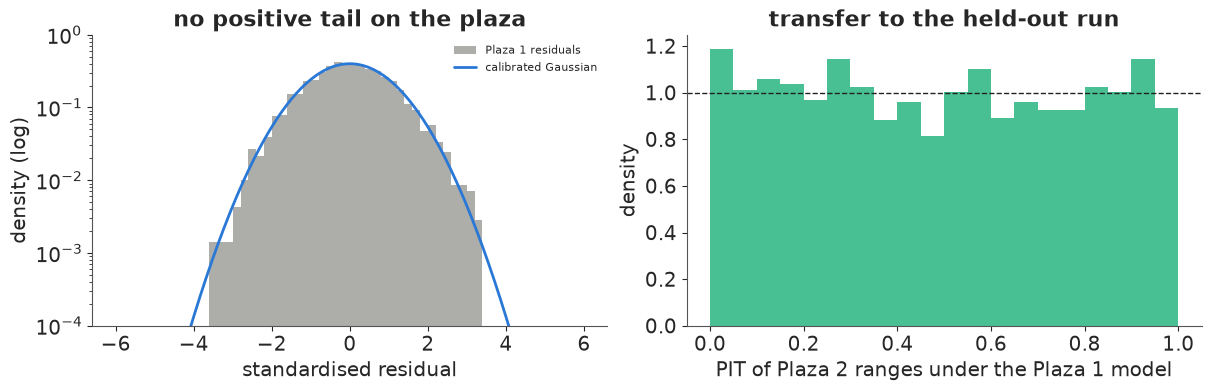

In [8]:
post = az.extract(idata_scale, var_names=["kappa", "beta", "sigma"], num_samples=1000, random_seed=RANDOM_SEED)
KAPPA, BETA, SIGMA = post["kappa"].values, post["beta"].values.T, post["sigma"].values   # BETA: (draw, beacon)
pn = az.extract(idata_nlos, var_names=["pi_nlos", "tau"])
z1 = (res1 - (KAPPA.mean() * d1 + BETA.mean(0)[j1])) / SIGMA.mean()
print(f"standardised Plaza 1 residuals: sd {z1.std():.2f}, share beyond +3 sd {np.mean(z1 > 3):.4f}, "
      f"beyond -3 sd {np.mean(z1 < -3):.4f} (Gaussian: 0.0013 each); largest {z1.max():.1f}, smallest {z1.min():.1f}")
print(f"NLOS share: posterior mean {pn['pi_nlos'].mean():.4f}, 97% quantile {np.quantile(pn['pi_nlos'], 0.97):.4f}")

# Transfer: Plaza 2 is a different day with the beacons moved; the same radios (ids) are used.
r2, d2, j2 = P2["r"], P2["d"], P2["j"]
pred2 = (1 + KAPPA[:, None]) * d2 + BETA[:, j2]
pit2 = ndtr((r2 - pred2) / SIGMA[:, None]).mean(0)
print(f"Plaza 2 (held out): {len(r2)} ranges; central 50% intervals cover {np.mean(np.abs(pit2 - 0.5) < 0.25):.1%}, "
      f"90% cover {np.mean(np.abs(pit2 - 0.5) < 0.45):.1%}")

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
xx = np.linspace(-6, 6, 400)
axs[0].hist(z1, bins=np.linspace(-6, 6, 61), density=True, color=GREY, alpha=0.7, label="Plaza 1 residuals")
axs[0].plot(xx, np.exp(-0.5 * xx**2) / np.sqrt(2 * np.pi), color=BLUE, lw=2, label="calibrated Gaussian")
axs[0].set_yscale("log")
axs[0].set(ylim=(1e-4, 1), xlabel="standardised residual", ylabel="density (log)",
           title="no positive tail on the plaza")
axs[0].legend(fontsize=8)
axs[1].hist(pit2, bins=20, range=(0, 1), density=True, color=AQUA, alpha=0.8)
axs[1].axhline(1, color=INK, ls="--", lw=1)
axs[1].set(xlabel="PIT of Plaza 2 ranges under the Plaza 1 model", ylabel="density",
           title="transfer to the held-out run");

## 3 · Odometry, and a gyro that drifts

Between pings the filter moves its particles with the odometry, so it needs to know how far to
trust it. We cut Plaza 1 into one-second windows, add up the odometry steps $(\Delta s_k \cos\theta_k,
\Delta s_k \sin\theta_k)$ in each to get the odometry displacement $u$, and compare it with the GPS
displacement $g$:

$$g = s\,R(\alpha)\,u + \eta, \qquad \eta \sim \mathcal N\!\left(0, (\sigma_0^2 + \sigma_1^2 \lVert u
\rVert) I\right),$$

with a distance scale $s$, a fixed "crab" angle $\alpha$ between where the robot points and where it
goes, and noise that grows with the square root of the distance travelled (a random walk per metre).
Windows in which the robot moved less than 20 cm are left out.

In [9]:
def window_displacements(R, W=1.0):
    """GPS displacement and odometry displacement (rotated by the odometry heading) in W-second windows."""
    gt, dr, drp = R["gt"], R["dr"], R["drp"]
    th = drp[:-1, 3]                          # heading at the start of each odometry step
    step = dr[:, 1][:, None] * np.c_[np.cos(th), np.sin(th)]
    w = ((dr[:, 0] - dr[0, 0]) // W).astype(int)
    n = w.max() + 1
    d_odo = np.c_[np.bincount(w, step[:, 0], n), np.bincount(w, step[:, 1], n)]
    gstep = np.diff(gt[:, 1:3], axis=0)
    d_gps = np.c_[np.bincount(w, gstep[:, 0], n), np.bincount(w, gstep[:, 1], n)]
    return d_gps, d_odo


dg, do = window_displacements(P1)
L = np.hypot(*do.T)
moving = L > 0.2
dg, do, L = dg[moving], do[moving], L[moving]
with pm.Model() as m_odo:
    s = pm.Normal("s", 1.0, 0.05)                    # distance scale
    alpha = pm.Normal("alpha", 0.0, 0.1)             # crab angle (rad)
    sig0 = pm.HalfNormal("sig0", 0.1)                # noise per window (m)
    sig1 = pm.HalfNormal("sig1", 0.1)                # noise per sqrt(metre)
    c, sn = pt.cos(alpha), pt.sin(alpha)
    mu = s * pt.stack([c * do[:, 0] - sn * do[:, 1], sn * do[:, 0] + c * do[:, 1]], axis=1)
    sd = pt.sqrt(sig0**2 + sig1**2 * L)[:, None]
    pm.Normal("d_gps", mu, sd, observed=dg)
    idata_odo = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
print(az.summary(idata_odo, round_to=4))
print(f"divergences {int(idata_odo.sample_stats['diverging'].sum())}")
ODO = {k: float(idata_odo.posterior[k].mean()) for k in ("s", "alpha", "sig0", "sig1")}

         mean      sd  eti89_lb  eti89_ub   ess_bulk   ess_tail   r_hat  mcse_mean  mcse_sd
s      0.9968  0.0009    0.9954    0.9983  3654.2767  2716.7752  1.0013        0.0      0.0
alpha -0.0182  0.0009   -0.0197   -0.0167  3873.8761  3173.7630  1.0000        0.0      0.0
sig0   0.0269  0.0013    0.0248    0.0290  1416.5911  1844.4448  1.0004        0.0      0.0
sig1   0.0310  0.0011    0.0292    0.0328  1463.6085  1906.6948  1.0003        0.0      0.0
divergences 0


The odometry is good on Plaza 1: distances are 0.3% short ($s$ = 0.997), the robot crabs about one
degree ($\alpha$ = -0.018 rad), and the noise is 2.7 cm per window plus 3.1 cm per square-root metre, added in quadrature.
All four parameters are sharply identified (r_hat 1.00, no divergences). The filter will use the
per-metre noise. But there is a catch, and it is in the next cell: Plaza 1's odometry heading is not
a gyro at all. It is exactly the GPS/INS heading, so Plaza 1 cannot tell us how a real
heading sensor drifts. Plaza 2's can.

Plaza 2: odometry heading falls behind the true direction of travel by 0.30 deg/s (121 deg over the run); Plaza 1: 0.0003 deg/s
Plaza 1's odometry heading minus its GPS/INS heading: largest absolute difference 0.0e+00 rad


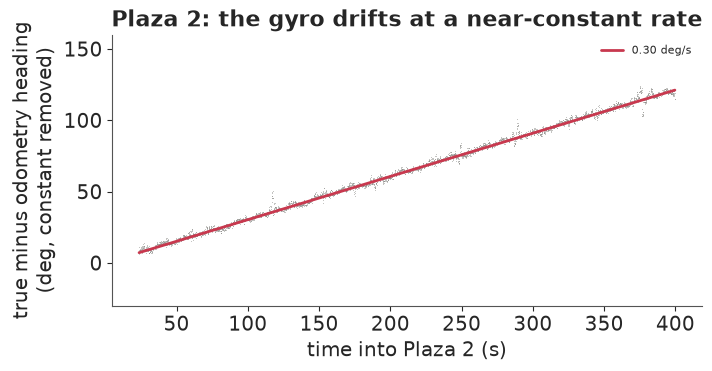

In [10]:
# Plaza 2's dead-reckoned heading against the direction the GPS says the vehicle moved
gt2, drp2 = P2["gt"], P2["drp"]
v = np.diff(gt2[:, 1:3], axis=0)
mv = np.hypot(*v.T) > 0.2
gap = np.unwrap(np.arctan2(v[:, 1], v[:, 0])[mv] - drp2[:-1, 3][mv])
tt = gt2[:-1, 0][mv] - gt2[0, 0]
rate, icpt = np.polyfit(tt, gap, 1)
dg1, do1 = window_displacements(P1)
th1 = np.arctan2(dg1[:, 1], dg1[:, 0]) - np.arctan2(do1[:, 1], do1[:, 0])
mv1 = np.hypot(*do1.T) > 0.2
rate1 = np.polyfit(np.arange(len(th1))[mv1], np.angle(np.exp(1j * th1[mv1])), 1)[0]   # 1-s windows
print(f"Plaza 2: odometry heading falls behind the true direction of travel by {np.degrees(rate):.2f} deg/s "
      f"({np.degrees(rate * (tt[-1])):.0f} deg over the run); Plaza 1: {np.degrees(rate1):.4f} deg/s")
print(f"Plaza 1's odometry heading minus its GPS/INS heading: largest absolute difference "
      f"{np.abs(np.angle(np.exp(1j * (P1['drp'][:, 3] - P1['gt'][:, 3])))).max():.1e} rad")
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(tt, np.degrees(gap - icpt), ",", color=GREY, alpha=0.5)
ax.plot(tt, np.degrees(rate * tt), color=RED, lw=2, label=f"{np.degrees(rate):.2f} deg/s")
ax.set(xlabel="time into Plaza 2 (s)", ylabel="true minus odometry heading\n(deg, constant removed)",
       title="Plaza 2: the gyro drifts at a near-constant rate", ylim=(-30, 160))
ax.legend(fontsize=8);

Plaza 2's odometry heading falls behind the direction the vehicle actually moved at a steady 0.30
degrees a second, 121 degrees over the run - the rosette in the first figure. A gyro with a constant
bias does exactly this. Plaza 1 shows nothing of the kind (its slope is zero to three decimals) and
its odometry heading is the INS heading itself (largest difference 0), so a calibration taken from Plaza 1 alone would
tell the filter to trust a heading that is wrong by three degrees within ten seconds. We do not use
this GPS comparison in the filter - it would be calibrating on the test run. Instead the filter
carries the gyro bias as an unknown, one more number per particle, with a prior sd of 0.01 rad/s
(0.6 deg/s) and a slow random walk, and learns it from the ranges. Section 6 checks what it learned
against the 0.30 deg/s seen here. One caveat belongs here. That prior, the heading noise below and
the resetting settings of the next part were chosen while developing the filter on Plaza 2, with this
drift already in view: the prior sd is about twice the drift. They are not fitted, but they are not
blind either. The policy comparison is relative - every rule runs the same filter - so it leans on
these settings less than the absolute errors do.

## 4 · A particle filter for ring-shaped beliefs

The robot's state is $x_t = (p_t, \theta_t, b_t)$: position, heading, gyro bias. A Bayes filter
alternates two steps. **Predict** moves the belief with the odometry: each odometry step of length
$\Delta s$ and heading change $\Delta\theta$ becomes

$$\theta \leftarrow \theta + \Delta\theta + b\,\Delta t + \epsilon_\theta, \qquad
p \leftarrow p + \Delta s\,(1 + \epsilon_s)\,(\cos\theta, \sin\theta) + \epsilon_p,$$

with $\epsilon_p$ of sd 0.031 m per square-root metre from the odometry model, 2% distance noise,
and heading noise of 0.02 rad per square-root second (a choice, since Plaza 1 had no gyro to
calibrate it on). **Update** reweights the belief by the likelihood of a range from beacon $j$,

$$p(r \mid x) = \mathcal N\!\left(r \,\middle|\, (1 + \kappa)\lVert p - b_j\rVert + \beta_j,\;
\sigma^2\right),$$

with the posterior means from the scale model ($\kappa$ = 0.069, $\sigma$ = 0.54 m). For a single
range this likelihood is a **ring** of radius $(r - \beta_j)/(1 + \kappa)$ and width about one metre.
A particle filter represents the belief by $N$ particles $x^{(k)}$ with weights $w^{(k)}$; predict
moves each particle with its own random noise, update multiplies each weight by the likelihood, and
when the weights become too uneven (effective sample size below $N/2$) the particles are resampled
in proportion to their weights, with a little jitter so that duplicates spread out again.

The robot is switched on **somewhere** - anywhere in a 95 m square around the beacons, facing any
way, with an unknown gyro bias - so the filter starts from 10,000 particles spread uniformly. First
we let it see every logged range, from 5 s into Plaza 2.

filter settings from the posterior means: scale 1.0694, offsets [0.02 0.06 0.04 0.01] m, range sd 0.54 m; odometry noise 0.031 m per sqrt(m)
after  1 ranges (t =   5.0 s): error of the mean  13.8 m, mass within 3 m of the truth 0.03
after  2 ranges (t =   5.3 s): error of the mean  17.7 m, mass within 3 m of the truth 0.42
after  3 ranges (t =   5.7 s): error of the mean   0.6 m, mass within 3 m of the truth 1.00
after  5 ranges (t =   6.1 s): error of the mean   0.6 m, mass within 3 m of the truth 1.00


after 12 ranges (t =   7.6 s): error of the mean   0.6 m, mass within 3 m of the truth 1.00


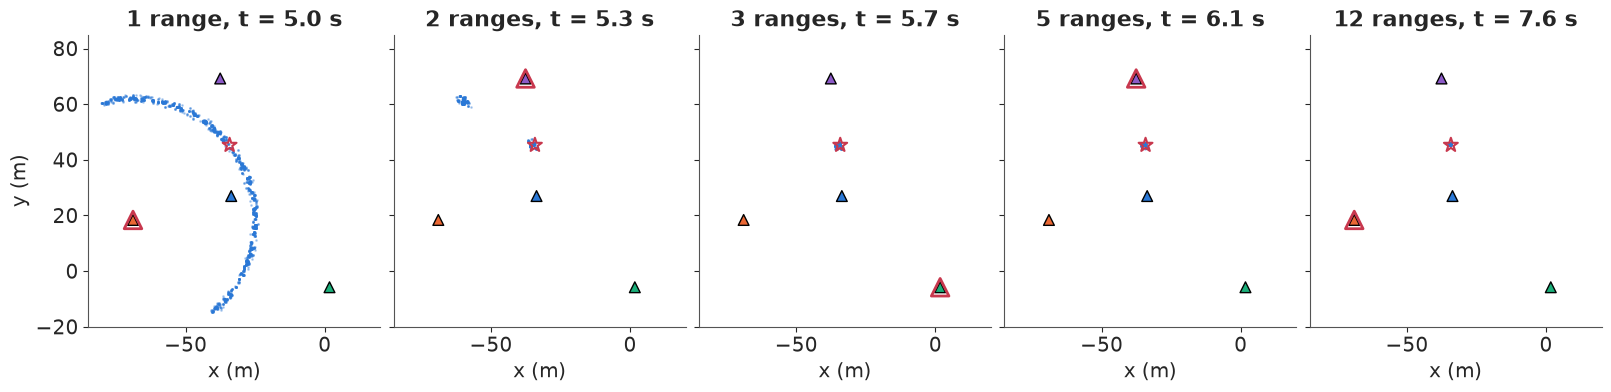

In [11]:
SCALE = 1 + KAPPA.mean()
OFFSET = BETA.mean(0)                       # per beacon id, from Plaza 1
SIG_R = SIGMA.mean()
STEP_SD, POS_SD = 0.02, ODO["sig1"]
HEAD_SD, BIAS_SD0, BIAS_RW = 0.02, 0.01, 0.0005   # heading noise (rad/sqrt s), gyro bias prior and walk
BXY2 = P2["bxy"]
TD2, J2, ODO_T = P2["td"], P2["j"], P2["dr"][:, 0]
BOX_LO, BOX_HI = np.array([-80.0, -15.0]), np.array([15.0, 80.0])   # where the robot might be switched on
T0_2 = P2["gt"][0, 0]
truth2 = P2["xy_at"]
print(f"filter settings from the posterior means: scale {SCALE:.4f}, offsets {np.round(OFFSET, 2)} m, "
      f"range sd {SIG_R:.2f} m; odometry noise {POS_SD:.3f} m per sqrt(m)")


def predicted_range(xy, j):
    return OFFSET[j] + SCALE * np.hypot(xy[..., 0] - BXY2[j, 0], xy[..., 1] - BXY2[j, 1])


class ParticleFilter:
    """Bootstrap particle filter over (x, y, heading, gyro bias), driven by Plaza 2's odometry."""

    def __init__(self, n, t_start, rng, reset=True, start=None):
        self.n, self.rng, self.reset = n, rng, reset
        P = np.empty((n, 4))
        if start is None:                                     # switched on somewhere in the box
            P[:, :2] = BOX_LO + (BOX_HI - BOX_LO) * rng.random((n, 2))
            P[:, 2] = rng.uniform(-np.pi, np.pi, n)
        else:                                                 # known start (x, y, heading)
            P[:, :2] = start[:2] + rng.normal(0, 0.3, (n, 2))
            P[:, 2] = start[2] + rng.normal(0, 0.05, n)
        P[:, 3] = rng.normal(0, BIAS_SD0, n)
        self.P, self.logw = P, np.zeros(n)
        self.k = np.searchsorted(ODO_T, t_start)
        self.resets = 0

    def predict_to(self, t):
        P, n, dr = self.P, self.n, P2["dr"]
        while self.k < len(ODO_T) and ODO_T[self.k] <= t:
            _, dist, dth = dr[self.k]
            dt = ODO_T[self.k] - ODO_T[self.k - 1]
            e = self.rng.standard_normal((5, n))
            P[:, 2] += dth + P[:, 3] * dt + HEAD_SD * np.sqrt(dt) * e[0]
            P[:, 3] += BIAS_RW * np.sqrt(dt) * e[1]
            step = dist * (1 + STEP_SD * e[2])
            P[:, 0] += step * np.cos(P[:, 2]) + POS_SD * np.sqrt(dist) * e[3]
            P[:, 1] += step * np.sin(P[:, 2]) + POS_SD * np.sqrt(dist) * e[4]
            self.k += 1

    def weights(self):
        w = np.exp(self.logw - self.logw.max())
        return w / w.sum()

    def mean(self):
        return self.weights() @ self.P[:, :2]

    def loglik(self, r, j, P=None):
        P = self.P if P is None else P
        return -0.5 * ((r - predicted_range(P[:, :2], j)) / SIG_R) ** 2

    def update(self, r, j):
        ll = self.loglik(r, j)
        if self.reset and ll.max() < -4.5:
            # no particle explains this range within 3 sd: redraw 5% of them on its ring
            m = self.n // 20
            idx = self.rng.choice(self.n, m, replace=False)
            rad = (r - OFFSET[j]) / SCALE + SIG_R * self.rng.standard_normal(m)
            ang = self.rng.uniform(-np.pi, np.pi, m)
            self.P[idx, :2] = BXY2[j] + rad[:, None] * np.c_[np.cos(ang), np.sin(ang)]
            self.P[idx, 2] = self.rng.uniform(-np.pi, np.pi, m)
            self.P[idx, 3] = self.rng.normal(0, BIAS_SD0, m)
            self.logw[idx] = self.logw.max()
            ll = self.loglik(r, j)
            self.resets += 1
        self.logw += ll
        w = self.weights()
        if 1 / np.sum(w**2) < self.n / 2:                     # systematic resampling + a little jitter
            u = (self.rng.random() + np.arange(self.n)) / self.n
            idx = np.minimum(np.searchsorted(np.cumsum(w), u), self.n - 1)
            self.P = self.P[idx]
            self.P[:, :2] += self.rng.normal(0, 0.1, (self.n, 2))
            self.P[:, 2] += self.rng.normal(0, 0.02, self.n)
            self.logw = np.zeros(self.n)

    def copy(self, rng):
        new = object.__new__(type(self))
        new.__dict__.update(self.__dict__)
        new.P, new.logw, new.rng = self.P.copy(), self.logw.copy(), rng
        return new


# Global localisation with every logged range, from the first 12 s of Plaza 2
pf = ParticleFilter(10_000, T0_2 + 5, np.random.default_rng(1))
snaps, n_used = [], 0
for i in np.where((TD2[:, 0] >= T0_2 + 5) & (TD2[:, 0] < T0_2 + 17))[0]:
    pf.predict_to(TD2[i, 0])
    pf.update(TD2[i, 3], J2[i])
    n_used += 1
    if n_used in (1, 2, 3, 5, 12):
        w = pf.weights()
        keep = pf.rng.choice(pf.n, 2000, p=w)
        snaps.append((n_used, TD2[i, 0] - T0_2, pf.P[keep, :2].copy(), truth2(TD2[i, 0])[0], J2[i]))
        print(f"after {n_used:2d} ranges (t = {TD2[i, 0] - T0_2:5.1f} s): error of the mean "
              f"{np.hypot(*(pf.mean() - truth2(TD2[i, 0])[0])):5.1f} m, "
              f"mass within 3 m of the truth {w[np.hypot(*(pf.P[:, :2] - truth2(TD2[i, 0])[0]).T) < 3].sum():.2f}")

fig, axs = plt.subplots(1, 5, figsize=(16, 3.8), sharex=True, sharey=True)
for ax, (n_, t_, S, tr, j) in zip(axs, snaps):
    ax.scatter(S[:, 0], S[:, 1], s=1, alpha=0.3, color=BLUE, rasterized=True)
    ax.scatter(*BXY2.T, marker="^", s=60, c=[BCOL[b] for b in BEACON_IDS], edgecolor="k", zorder=4)
    ax.scatter(*BXY2[j], marker="^", s=160, facecolor="none", edgecolor=RED, lw=2, zorder=5)
    ax.scatter(*tr, marker="*", s=110, facecolor="none", edgecolor=RED, lw=1.5, zorder=6)
    ax.set(title=f"{n_} range{'s' if n_ > 1 else ''}, t = {t_:.1f} s", aspect="equal",
           xlim=(-85, 20), ylim=(-20, 85), xlabel="x (m)")
axs[0].set_ylabel("y (m)");

The pictures are the geometry of range-only sensing. After one range (from beacon 1, ringed in
red) the particles that keep their weight form an arc of the ring around it - an arc, not a full
circle, because the rest of the circle lies outside the box the robot could be in. The error of the
belief's mean is 14 m, which means nothing: the mean of a ring is a point where the robot certainly
is not. After the second range (beacon 6) two blobs are left, where the two circles cross, and
only 42% of the mass is near the truth. The third range, from beacon 5 on the far side, kills the
wrong blob, and from then on the mean is within 0.6 m. With four ranges a second, finding the robot
takes under a second.

Now the budget: **one range every two seconds**, about one in nine of what the radios logged. The
rest of the notebook replays Plaza 2 in 40-second episodes that start every 20 s (19 start times,
two random seeds each, so 38 episodes per rule), each with the robot switched on somewhere unknown.
We score each episode by its **lock time**, the time after which the error of the belief's mean
stays below 3 m to the end of the episode (40 s means it never locked), and by how often most of the
belief's mass sits more than 3 m from the truth.

Under that budget the filter meets its own failure before any clever choosing. **Failure 2: sure
and wrong.** With pings arriving slowly, the particles can all collapse onto a wrong blob that
happened to fit the first few ranges. After that, no particle is near the truth, and a range that
contradicts every particle only reweights wrong particles against each other; the filter never
recovers. The standard fix is **sensor resetting** (Lenser & Veloso 2000): when no particle explains
a range to within 3 sd, redraw 5% of the particles on that range's ring, with random headings, so
the filter has somewhere new to go. We compare the plain round-robin schedule (beacons 0, 1, 5, 6 in
turn) with and without it.

In [12]:
def kmeans_modes(pf, rng, m=2000):
    """Two-cluster summary of the belief: centres, masses, and within-cluster spread."""
    S = pf.P[rng.choice(pf.n, m, p=pf.weights()), :2]
    cent, lab = kmeans2(S, 2, seed=rng.integers(2**31), minit="++")
    mass = np.bincount(lab, minlength=2) / m
    spread = np.array([S[lab == c].std(0).max() if mass[c] > 0 else np.nan for c in range(2)])
    return cent, mass, spread


def wrong_mass(pf, t):
    return pf.weights()[np.hypot(*(pf.P[:, :2] - truth2(t)[0]).T) > 3].sum()


def eig_scores(pf, cands, rng, m=300):
    """Expected information gain I(z_j; x) of each candidate beacon, by nested Monte Carlo."""
    S = pf.P[rng.choice(pf.n, m, p=pf.weights()), :2]
    out = []
    for j in cands:
        h = predicted_range(S, j)
        z = h + SIG_R * rng.standard_normal(m)
        log_cond = -0.5 * ((z - h) / SIG_R) ** 2
        log_marg = np.log(np.mean(np.exp(-0.5 * ((z[:, None] - h[None, :]) / SIG_R) ** 2), axis=1))
        out.append(np.mean(log_cond - log_marg))
    return np.array(out)


def spread_scores(pf, cands, rng, m=1000):
    """Variance of the predicted range across the belief."""
    S = pf.P[rng.choice(pf.n, m, p=pf.weights()), :2]
    return np.array([predicted_range(S, j).var() for j in cands])


def choose(policy, pf, avail, state, rng):
    if policy == "round-robin":
        j = next(o for o in [(state["rr"] + q) % 4 for q in range(4)] if o in avail)
        state["rr"] = (j + 1) % 4
        return j
    if policy == "random":
        return rng.choice(avail)
    if policy == "nearest":
        return avail[np.argmin(np.hypot(*(BXY2[avail] - pf.mean()).T))]
    if policy == "spread":
        return avail[np.argmax(spread_scores(pf, avail, rng))]
    if policy == "EIG":
        return avail[np.argmax(eig_scores(pf, avail, rng))]
    raise ValueError(policy)


def replay(policy, t_start, dur, W, n, seed, reset=True, start=None, hook=None):
    """Replay Plaza 2 from t_start: in each W-second window reveal ONE logged range, chosen by the policy,
    from the beacons that have a range in that window ('all' reveals every range). Returns per-window
    error of the posterior mean, mass more than 3 m from the truth, the chosen beacons, and the filter."""
    rng = np.random.default_rng(seed)
    pf = ParticleFilter(n, t_start, rng, reset=reset, start=start)
    err, wrong, picks, state = [], [], [], {"rr": 0}
    for w in range(int(round(dur / W))):
        a, b = t_start + w * W, t_start + (w + 1) * W
        rows = np.where((TD2[:, 0] >= a) & (TD2[:, 0] < b))[0]
        avail = np.unique(J2[rows])
        pf.predict_to(a)
        if policy == "all":
            for i in rows:
                pf.predict_to(TD2[i, 0])
                pf.update(TD2[i, 3], J2[i])
        elif len(avail):
            if hook is not None:
                hook(pf, w, avail, rows, a)
            j = choose(policy, pf, avail, state, rng)
            i = rows[J2[rows] == j][0]                        # the first range from that beacon in the window
            pf.predict_to(TD2[i, 0])
            pf.update(TD2[i, 3], j)
            picks.append(j)
        pf.predict_to(b)
        err.append(np.hypot(*(pf.mean() - truth2(b)[0])))
        wrong.append(wrong_mass(pf, b))
    return np.array(err), np.array(wrong), np.array(picks), pf


W, DUR, N_PART = 2.0, 40.0, 10_000
STARTS = T0_2 + np.arange(5, 370, 20.0)
SEEDS = [0, 1]


def lock_time(err, W=W, tol=3.0):
    """Seconds until the error of the posterior mean drops below tol for the rest of the episode."""
    bad = np.where(err >= tol)[0]
    return (bad[-1] + 1) * W if len(bad) else 0.0


def sweep(policy, W=W, reset=True, seeds=SEEDS, hook=None):
    E, Wr, P = [], [], []
    for si, s in enumerate(STARTS):
        for seed in seeds:
            if hook is not None:
                hook.episode = (si, seed)
            e, wr, pk, _ = replay(policy, s, DUR, W, N_PART, 1000 * si + seed, reset=reset, hook=hook)
            E.append(e), Wr.append(wr), P.append(pk)
    return np.array(E), np.array(Wr), P


t0 = time.time()
E_noreset, Wr_noreset, _ = sweep("round-robin", reset=False)
E_rr, Wr_rr, _ = sweep("round-robin")
print(f"{len(E_rr)} episodes each ({len(STARTS)} start times x {len(SEEDS)} seeds), {time.time() - t0:.0f} s")
for nm, E, Wr in (("without resetting", E_noreset, Wr_noreset), ("with resetting", E_rr, Wr_rr)):
    lt = np.array([lock_time(e) for e in E])
    print(f"round-robin {nm:18s}: never locked {np.mean(lt >= DUR):.0%}, median lock {np.median(lt):.0f} s, "
          f"mean error over the last 20 s {E[:, -10:].mean():.1f} m, "
          f"windows with most mass in a wrong place {np.mean(Wr > 0.5):.0%}")

38 episodes each (19 start times x 2 seeds), 23 s
round-robin without resetting : never locked 18%, median lock 17 s, mean error over the last 20 s 5.0 m, windows with most mass in a wrong place 36%
round-robin with resetting    : never locked 8%, median lock 16 s, mean error over the last 20 s 3.7 m, windows with most mass in a wrong place 34%


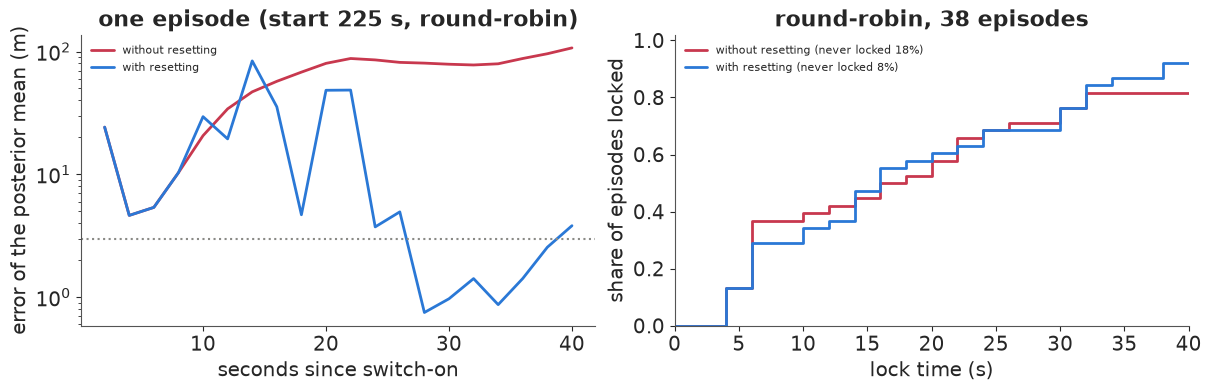

In [13]:
lt_no = np.array([lock_time(e) for e in E_noreset])
worst = int(np.argmax(lt_no + E_noreset[:, -1] / 1000))
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
tw = W * np.arange(1, E_rr.shape[1] + 1)
axs[0].semilogy(tw, E_noreset[worst], color=RED, lw=2, label="without resetting")
axs[0].semilogy(tw, E_rr[worst], color=BLUE, lw=2, label="with resetting")
axs[0].axhline(3, color=GREY, ls=":")
axs[0].set(xlabel="seconds since switch-on", ylabel="error of the posterior mean (m)",
           title=f"one episode (start {STARTS[worst // len(SEEDS)] - T0_2:.0f} s, round-robin)")
axs[0].legend(fontsize=8)
for nm, E, c in (("without resetting", E_noreset, RED), ("with resetting", E_rr, BLUE)):
    lt = np.sort([lock_time(e) for e in E])
    ok = lt < DUR                                           # episodes that never locked stay off the curve
    axs[1].step(np.r_[0, lt[ok], DUR], np.r_[0, np.arange(1, ok.sum() + 1), ok.sum()] / len(lt), where="post",
                color=c, lw=2, label=f"{nm} (never locked {np.mean(~ok):.0%})")
axs[1].set(xlabel="lock time (s)", ylabel="share of episodes locked", xlim=(0, DUR), ylim=(0, 1.02),
           title="round-robin, 38 episodes");
axs[1].legend(fontsize=8);

Without resetting, 18% of round-robin episodes never lock; with it, 8% do. The typical episode is
hardly affected (median lock 17 s against 16 s) - resetting does nothing until the filter is lost.
The left panel is the worst episode without resetting (start 225 s into the run): its error climbs
steadily to about 100 m as the confident wrong cloud follows the odometry off the plaza. With
resetting, the same episode jumps between candidate positions as rings are redrawn, gets within a
metre at about 28 s, and is drifting out again at 40 s - a rescue, but not a clean one. Every filter
from here on resets. The bigger point is in the right panel: even with a working filter, round-robin
takes a median of 16 s to find the robot, and a third of its windows have most of the mass in the
wrong place. That is what choosing better should improve.

## 5 · Which beacon to ping

At each decision the filter's particles are a sample from the current belief $p(x)$. Pinging beacon
$j$ will return a range $z_j$ whose distribution, before we see it, is the belief pushed through the
sensor model: $p(z_j) = \int p(z_j \mid x)\,p(x)\,dx$. The **expected information gain** is how much,
on average, seeing $z_j$ will shrink our uncertainty about $x$, measured by entropy. It equals the
mutual information between the reply and the state,

$$\mathrm{EIG}_j = I(z_j; x) = \mathbb E_{x \sim p(x),\; z \sim p(z \mid x)}\big[\log p(z \mid x) -
\log p(z)\big],$$

which we estimate by **nested Monte Carlo**: draw $m = 300$ particles $x_1, \dots, x_m$ by weight,
simulate one range $z_k$ from each, and approximate the marginal by the mixture over the same draws,
$p(z_k) \approx \frac1m \sum_l p(z_k \mid x_l)$. Because the range is one number with Gaussian noise
of known sd, EIG only depends on how the predicted ranges $h_j(x) = (1 + \kappa)\lVert p - b_j\rVert +
\beta_j$ are spread across the belief compared with $\sigma$. If they were Gaussian with variance $V_j$,
EIG would be $\tfrac12\log(1 + V_j/\sigma^2)$, an increasing function of $V_j$. So a much cheaper
rule - ping the beacon whose **predicted range has the largest spread** - picks the same beacon
whenever the predicted ranges are roughly Gaussian. They can differ when the belief has separate
clumps: a beacon whose predicted ranges are wide but smeared evenly can have the larger variance
and still separate the clumps less well than one that splits them cleanly.

Against these two we put three rules that need no belief at all, or almost none: **round-robin**
(each beacon in turn, skipping any that did not answer in the window), **random** (any beacon that
answered), and **nearest** (the beacon closest to the belief's mean, a common rule because a near
beacon has the strongest signal; here the noise does not grow with distance, so it buys nothing). The
ceiling is **all**: every logged range, about nine per window. Every rule has the same filter and
the same resetting, and for a given episode and seed every rule starts from the same particle cloud
(after the first decision their random streams part ways).

Alongside the EIG episodes we also look behind the choice, with counterfactual pings. At every
decision where more than half of the belief's mass is more than 3 m from the truth, we take each
candidate beacon in turn, apply its real logged range to a copy of the filter, and record where the
mass ends up. That tells us, for real ranges, which ping would have helped - something no policy
sees. We also score the candidates' EIG afresh from the same belief, so "the highest-EIG beacon"
below is that fresh score; where two candidates are close it need not be the one the episode pinged.

In [14]:
class CounterfactualPings:
    """At every decision where most of the belief is in the wrong place, try all candidate pings
    (each with its real logged range) on copies of the filter and record where the mass ends up.
    It does not touch the episode."""

    def __init__(self):
        self.moments, self.episode = [], None

    def __call__(self, pf, w, avail, rows, a):
        if len(avail) < 3 or wrong_mass(pf, a) < 0.5:
            return
        hr = np.random.default_rng(len(self.moments))
        after = []
        for j in avail:
            alt = pf.copy(np.random.default_rng(0))
            i = rows[J2[rows] == j][0]
            alt.predict_to(TD2[i, 0])
            alt.update(TD2[i, 3], j)
            after.append(wrong_mass(alt, TD2[i, 0]))
        cent, mass, spread = kmeans_modes(pf, hr)
        two_modes = mass.min() > 0.25 and np.hypot(*(cent[0] - cent[1])) > 8 and np.all(spread < 4)
        self.moments.append(dict(
            episode=self.episode, w=w, a=a, avail=avail, rows=rows, after=np.array(after),
            before=wrong_mass(pf, a), eig=eig_scores(pf, avail, hr), spread=spread_scores(pf, avail, hr),
            nearest=int(np.argmin(np.hypot(*(BXY2[avail] - pf.mean()).T))), two_modes=two_modes,
            pf=pf.copy(np.random.default_rng(0)) if two_modes else None))


POLICIES = ["all", "round-robin", "random", "nearest", "spread", "EIG"]
results = {"round-robin": (E_rr, Wr_rr)}
probe = CounterfactualPings()
t0 = time.time()
picks_eig = None
for pol in POLICIES:
    if pol not in results:
        E, Wr, Pk = sweep(pol, hook=probe if pol == "EIG" else None)
        results[pol] = (E, Wr)
        if pol == "EIG":
            picks_eig = Pk
print(f"policy sweep: {time.time() - t0:.0f} s")

policy sweep: 66 s


In [15]:
M = probe.moments
after_eig = np.array([m["after"][np.argmax(m["eig"])] for m in M])
after_spr = np.array([m["after"][np.argmax(m["spread"])] for m in M])
after_near = np.array([m["after"][m["nearest"]] for m in M])
after_rand = np.array([m["after"].mean() for m in M])
after_best = np.array([m["after"].min() for m in M])
after_worst = np.array([m["after"].max() for m in M])
print(f"{len(M)} decisions in the EIG episodes with more than half the mass more than 3 m from the truth "
      f"({sum(m['two_modes'] for m in M)} of them pass the two-cluster screen); mean mass in the wrong place:")
print(f"  before the ping {np.mean([m['before'] for m in M]):.2f}; after the highest-EIG ping {after_eig.mean():.2f}, "
      f"by spread {after_spr.mean():.2f}, at random (average over candidates) {after_rand.mean():.2f}, "
      f"nearest {after_near.mean():.2f}; best candidate {after_best.mean():.2f}, worst {after_worst.mean():.2f}")
mat = after_worst - after_best > 0.3
print(f"  in {mat.sum()} of them the choice mattered (best and worst candidates more than 0.3 apart); there, "
      f"EIG left {after_eig[mat].mean():.2f}, spread {after_spr[mat].mean():.2f}, random {after_rand[mat].mean():.2f}, "
      f"nearest {after_near[mat].mean():.2f} (best {after_best[mat].mean():.2f}, worst {after_worst[mat].mean():.2f}); "
      f"the highest-EIG ping was the best (within 0.05) in {np.mean(after_eig[mat] <= after_best[mat] + 0.05):.0%}, "
      f"the worst in {np.mean(after_eig[mat] >= after_worst[mat] - 0.05):.0%}")

206 decisions in the EIG episodes with more than half the mass more than 3 m from the truth (14 of them pass the two-cluster screen); mean mass in the wrong place:
  before the ping 0.95; after the highest-EIG ping 0.70, by spread 0.69, at random (average over candidates) 0.78, nearest 0.80; best candidate 0.59, worst 0.93
  in 81 of them the choice mattered (best and worst candidates more than 0.3 apart); there, EIG left 0.39, spread 0.38, random 0.56, nearest 0.61 (best 0.17, worst 0.89); the highest-EIG ping was the best (within 0.05) in 59%, the worst in 21%


episode starting at 345 s (seed 0), 20 s after switch-on; mass away from the truth before the ping 0.72
beacon 0: EIG 1.17 nats, predicted-range sd   1.6 m -> after its real range, mass more than 3 m from the truth 0.98
beacon 1: EIG 2.03 nats, predicted-range sd   5.7 m -> after its real range, mass more than 3 m from the truth 0.01
beacon 5: EIG 1.67 nats, predicted-range sd   4.6 m -> after its real range, mass more than 3 m from the truth 0.50
beacon 6: EIG 1.21 nats, predicted-range sd   2.1 m -> after its real range, mass more than 3 m from the truth 0.78


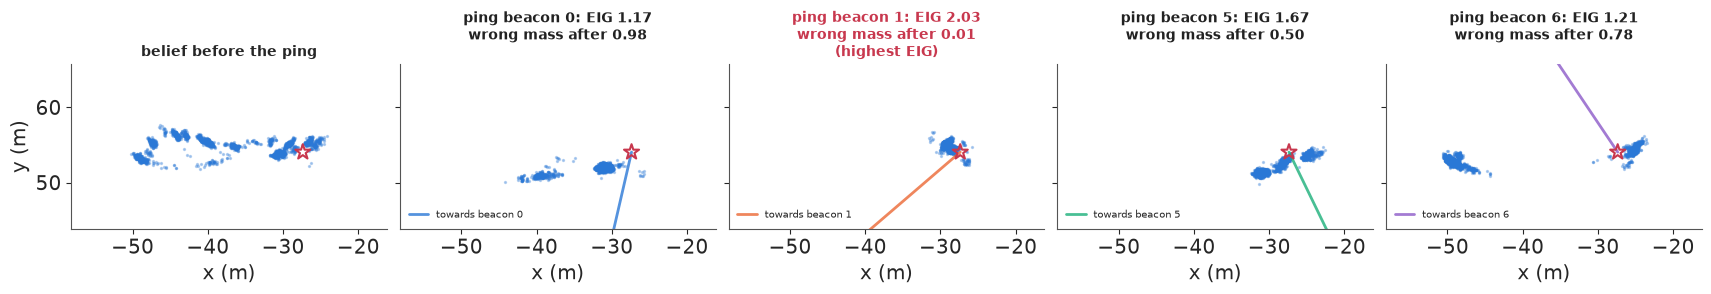

In [16]:
# of the moments that pass the two-cluster screen, the one where the candidates disagree most
# (chosen after looking at all of them)
cands = [m for m in M if m["two_modes"]]
mo = max(cands, key=lambda m: m["after"].max() - m["after"][np.argmax(m["eig"])])
pf0, rows, avail = mo["pf"], mo["rows"], mo["avail"]
tr = truth2(mo["a"])[0]
print(f"episode starting at {STARTS[mo['episode'][0]] - T0_2:.0f} s (seed {mo['episode'][1]}), "
      f"{(mo['w']) * W:.0f} s after switch-on; mass away from the truth before the ping {mo['before']:.2f}")
er = np.random.default_rng(5)
after = {}
for k, j in enumerate(avail):
    alt = pf0.copy(np.random.default_rng(0))
    i = rows[J2[rows] == j][0]
    alt.predict_to(TD2[i, 0])
    alt.update(TD2[i, 3], j)
    after[j] = alt
    print(f"beacon {BEACON_IDS[j]}: EIG {mo['eig'][k]:.2f} nats, predicted-range sd {np.sqrt(mo['spread'][k]):5.1f} m "
          f"-> after its real range, mass more than 3 m from the truth {mo['after'][k]:.2f}")

fig, axs = plt.subplots(1, 1 + len(avail), figsize=(3.4 * (1 + len(avail)), 4), sharex=True, sharey=True)
S0 = pf0.P[er.choice(pf0.n, 2000, p=pf0.weights()), :2]
lims = np.r_[np.minimum(S0.min(0), tr) - 8, np.maximum(S0.max(0), tr) + 8]
panels = [("belief before the ping", S0, None)] + [
    (f"ping beacon {BEACON_IDS[j]}: EIG {mo['eig'][k]:.2f}\nwrong mass after {mo['after'][k]:.2f}",
     after[j].P[er.choice(pf0.n, 2000, p=after[j].weights()), :2], j) for k, j in enumerate(avail)]
for ax, (title, S, j) in zip(axs, panels):
    ax.scatter(S[:, 0], S[:, 1], s=2, alpha=0.3, color=BLUE, rasterized=True)
    ax.scatter(*tr, marker="*", s=130, facecolor="none", edgecolor=RED, lw=1.5, zorder=6)
    if j is not None:
        u = (tr - BXY2[j]) / np.hypot(*(tr - BXY2[j]))            # direction to the beacon, drawn as a spoke
        ax.plot([tr[0], tr[0] - 30 * u[0]], [tr[1], tr[1] - 30 * u[1]], color=BCOL[BEACON_IDS[j]], lw=2,
                alpha=0.8, label=f"towards beacon {BEACON_IDS[j]}")
        best = j == avail[np.argmax(mo["eig"])]
        ax.set_title(title + ("\n(highest EIG)" if best else "\n"), fontsize=10, color=RED if best else INK)
        ax.legend(fontsize=7, loc="lower left")
    else:
        ax.set_title(title, fontsize=10)
    ax.set(xlim=(lims[0], lims[2]), ylim=(lims[1], lims[3]), aspect="equal", xlabel="x (m)")
axs[0].set_ylabel("y (m)");

The counterfactual pings found 206 decisions, across the 38 EIG episodes, at which most of the belief was in the
wrong place - nearly all of it (0.95 on average) before the ping. Most of the time no single ping
fixes that: even the best candidate leaves 0.59 of the mass in the wrong place on average, because
one range only removes the blobs that lie off its ring. But the candidates are not equal. The
highest-EIG ping left 0.70 on average, the spread rule's 0.69, a random pick 0.78 and the nearest beacon
0.80. In the 81 decisions where the choice really mattered (best and worst candidates more than
0.3 apart), the highest-EIG ping left 0.39 in the wrong place, the spread rule's 0.38, a random pick 0.56 and
the nearest beacon 0.61, against 0.17 for the best candidate and 0.89 for the worst. The
highest-EIG beacon was the best candidate 59% of the time and the worst 21% of the time: a one-step score from 300 particles
is a good guide, not an oracle.

The figure is one such decision. Of the 14 moments whose belief passes a two-cluster screen, it is
the one where the candidates disagree most, picked after looking at all of them. Twenty seconds after switch-on, in an episode starting 345 s
into the run, the belief is a string of clusters along a line, with the truth (star) at its right
end and 72% of the mass elsewhere. The clusters survived earlier pings because they lie at nearly
the same distance from beacons 0 and 6: those two beacons predict ranges that differ by only 1.6
and 2.1 m (sd) across the belief, three or four times the noise, and their real ranges leave 98%
and 78% of the mass in the wrong place. Beacon 1 sees the string end-on, at an angle, so its
distances to the clusters differ most: its predicted ranges differ by 5.7 m (sd); its EIG is the largest (2.03 nats), and its
real range leaves 1% of the mass in the wrong place. Beacon 5 is in between (EIG 1.67, 50% left).
This is the case information gain is for: the beacon to ask is the one that the hypotheses
disagree about, not the nearest and not the next in line.

In [17]:
rows_out = []
for pol in POLICIES:
    E, Wr = results[pol]
    lt = np.array([lock_time(e) for e in E])
    rows_out.append(dict(policy=pol, median_lock_s=np.median(lt), mean_lock_s=lt.mean(),
                         never_locked=np.mean(lt >= DUR), wrong_mode_windows=np.mean(Wr > 0.5),
                         error_last_20s_median_m=np.median(E[:, -10:]), error_last_20s_mean_m=E[:, -10:].mean()))
table = pd.DataFrame(rows_out).set_index("policy")
print(table.round(2))
lt_rr = np.array([lock_time(e) for e in results["round-robin"][0]])
lt_eig = np.array([lock_time(e) for e in results["EIG"][0]])
print(f"EIG vs round-robin, paired by episode: EIG faster in {np.mean(lt_eig < lt_rr):.0%}, "
      f"slower in {np.mean(lt_eig > lt_rr):.0%}, tied in {np.mean(lt_eig == lt_rr):.0%}; "
      f"mean difference {np.mean(lt_eig - lt_rr):+.1f} s")
for pol in ("spread", "EIG"):
    lt_ = np.array([lock_time(e) for e in results[pol][0]])
    print(f"{pol:6s} by seed: median lock seed 0 {np.median(lt_[0::2]):.0f} s, seed 1 {np.median(lt_[1::2]):.0f} s; "
          f"never locked seed 0 {np.sum(lt_[0::2] >= DUR)}, seed 1 {np.sum(lt_[1::2] >= DUR)} of 19")
print("EIG's share of pings per beacon:", {BEACON_IDS[j]: round(float(np.mean(np.concatenate(picks_eig) == j)), 2)
                                         for j in range(4)})

             median_lock_s  mean_lock_s  never_locked  wrong_mode_windows  error_last_20s_median_m  error_last_20s_mean_m
policy                                                                                                                   
all                    0.0         0.95          0.00                0.02                     0.30                   0.35
round-robin           16.0        18.84          0.08                0.34                     1.04                   3.70
random                13.0        16.00          0.00                0.31                     0.85                   2.42
nearest               40.0        36.05          0.74                0.88                    27.62                  26.89
spread                 5.0         9.05          0.00                0.21                     0.70                   1.17
EIG                    6.0         9.89          0.03                0.22                     0.79                   3.32
EIG vs round-robin, pair

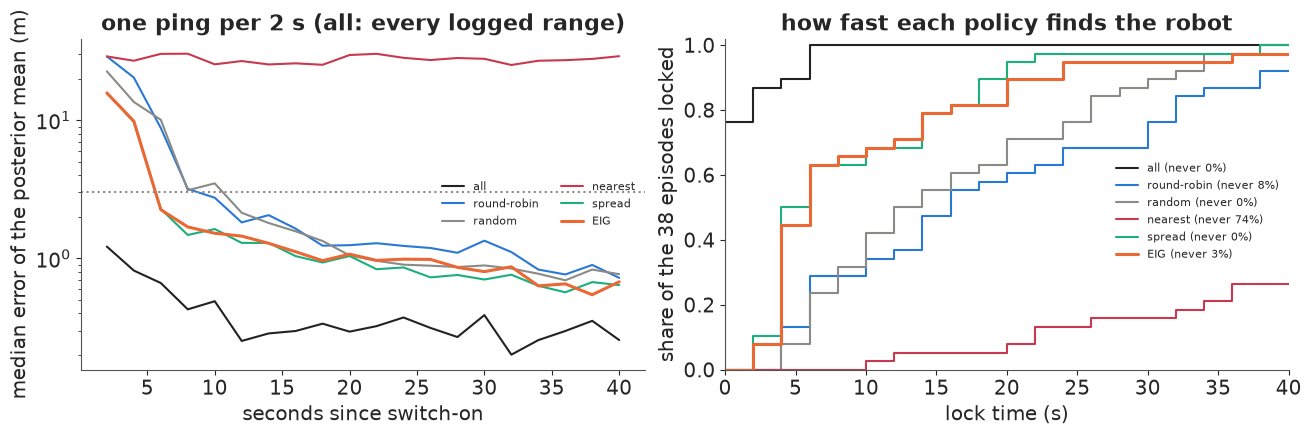

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
cols = {"all": INK, "round-robin": BLUE, "random": GREY, "nearest": RED, "spread": AQUA, "EIG": ORANGE}
for pol in POLICIES:
    E = results[pol][0]
    axs[0].semilogy(tw, np.median(E, axis=0), color=cols[pol], lw=2.2 if pol == "EIG" else 1.5, label=pol)
    lt = np.sort([lock_time(e) for e in E])
    ok = lt < DUR                                           # never-locked episodes stay off the curve
    axs[1].step(np.r_[0, lt[ok], DUR], np.r_[0, np.arange(1, ok.sum() + 1), ok.sum()] / len(lt), where="post",
                color=cols[pol], lw=2.2 if pol == "EIG" else 1.5, label=f"{pol} (never {np.mean(~ok):.0%})")
axs[0].axhline(3, color=GREY, ls=":")
axs[0].set(xlabel="seconds since switch-on", ylabel="median error of the posterior mean (m)",
           title="one ping per 2 s (all: every logged range)")
axs[1].set(xlabel="lock time (s)", ylabel="share of the 38 episodes locked", xlim=(0, DUR), ylim=(0, 1.02),
           title="how fast each policy finds the robot")
axs[0].legend(fontsize=8, ncol=2)
axs[1].legend(fontsize=8, loc="lower right", bbox_to_anchor=(1, 0.3));

Over all 38 episodes, the two belief-based rules find the robot two to three times as fast as the
rules that ignore the belief. EIG's median lock time is 6 s and the spread rule's 5 s, against 13 s
for random and 16 s for round-robin. Paired episode by episode, EIG locked sooner than round-robin
in 68% of episodes and later in 8%, and 9 s sooner on average. Most of the belief's mass sat in the
wrong place in 22% of EIG's windows and 34% of round-robin's. Once locked, the rules are close: the
median error over the last 20 s is 0.7-1.0 m for all four reasonable rules, against 0.3 m for the
ceiling that sees every range. EIG's *mean* error over the last 20 s (3.3 m) is inflated by its one
episode of 38 that never locked; the spread rule had none. EIG did not favour a beacon overall -
its pings went 24%, 31%, 23% and 22% to beacons 0, 1, 5 and 6 - it favoured the right beacon at
the right moment.

**Nearest is a trap.** It never locked in 74% of episodes, and its median error stays near 30 m.
The belief's mean is in the wrong place early on, so the "nearest" beacon is nearest to the wrong
place; and once a beacon is chosen as nearest it tends to stay chosen, so the filter hears from the
same beacon again and again - and repeated ranges from one beacon only ever describe a ring. The
rule that sounds most sensible to an engineer is the one that most needs the others.

The spread rule did as well as EIG here, slightly better on every line of the table. But the two
differ by one episode in "never locked" and by a second in median lock time, and the seed split
shows two seconds between seed 0 and seed 1 for the spread rule alone (6 s against 4 s).
That is too little to separate them with 38 episodes that overlap: two seeds share each start, and
episodes starting every 20 s share half their 40 s of data, so there are nearer 10-19 independent
ones. What we can say is that on this problem the cheap rule loses nothing we can measure.
Ranges are one-dimensional with constant Gaussian noise, and the predicted range's spread captures
most of what the full mutual information adds.

Is the gain a feature of the tight budget? We repeat the round-robin and EIG sweeps with one ping
per second (one seed, to keep the run time down).

In [19]:
t0 = time.time()
E1_rr, _, _ = sweep("round-robin", W=1.0, seeds=[0])
E1_eig, _, _ = sweep("EIG", W=1.0, seeds=[0])
lt1_rr = np.array([lock_time(e, W=1.0) for e in E1_rr])
lt1_eig = np.array([lock_time(e, W=1.0) for e in E1_eig])
lt2_rr, lt2_eig = lt_rr[::2], lt_eig[::2]
print(f"one ping per second ({time.time() - t0:.0f} s): mean lock round-robin {lt1_rr.mean():.1f} s, "
      f"EIG {lt1_eig.mean():.1f} s (seed 0 only)")
print(f"one ping per 2 s, same 19 episodes:      mean lock round-robin {lt2_rr.mean():.1f} s, "
      f"EIG {lt2_eig.mean():.1f} s")

one ping per second (14 s): mean lock round-robin 7.9 s, EIG 4.0 s (seed 0 only)
one ping per 2 s, same 19 episodes:      mean lock round-robin 17.8 s, EIG 12.0 s


With twice the budget both rules lock sooner, and EIG still takes about half as long as
round-robin: 4.0 s against 7.9 s on average over the 19 seed-0 episodes. At one ping per 2 s the
same 19 episodes take 12.0 s against 17.8 s. Choosing well pays in both regimes; the saving in
seconds is larger when pings are scarcer.

## 6 · Fusion on the whole run

Lock time is about the first seconds. The other half of the story is what the chosen pings do over
a long drive, against the odometry alone. We switch the robot on 5 s into Plaza 2, again with no
idea where it is, and run the filter to the end of the log with EIG choosing one ping per 2 s. For
the odometry we give it every advantage: its dead-reckoned path starts at the *true* position and
heading.

402 s of Plaza 2 with 201 pings (11% of the logged ranges), 4 s
locked after 22 s; afterwards error median 0.53 m, 95th percentile 1.13 m, max 2.8 m; odometry alone (from the true start): median 25.7 m, max 72 m
gyro bias learned by the filter at the end: 0.25 deg/s (the GPS comparison above: 0.30 deg/s)


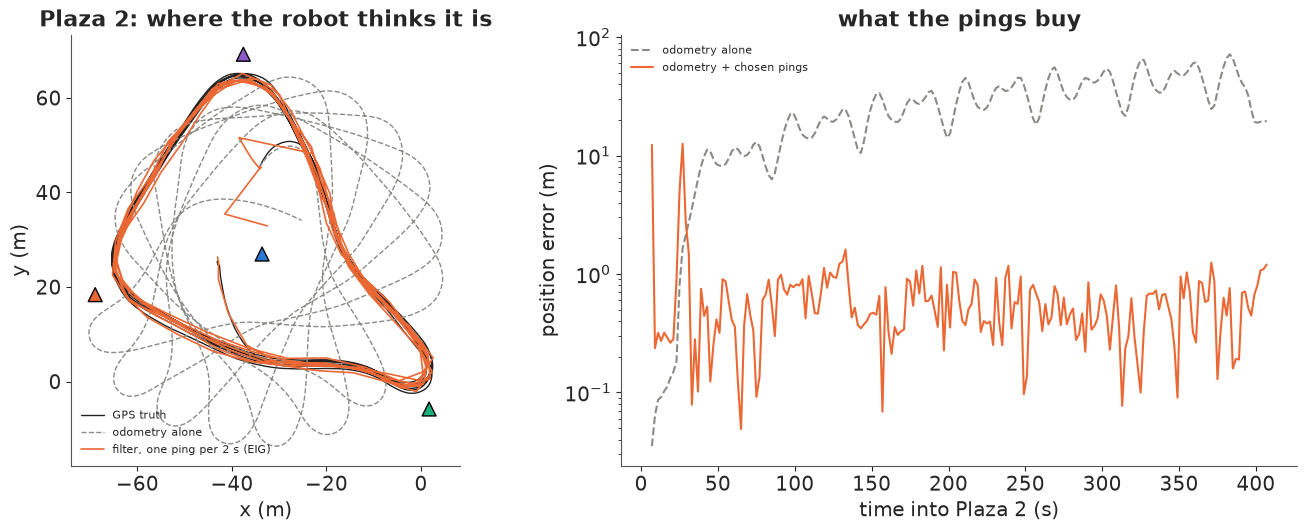

In [20]:
t0 = time.time()
DUR_FULL = 2 * np.floor((P2["gt"][-1, 0] - T0_2 - 6) / 2)
track, bias_trace = [], []


def record(pf, w, avail, rows, a):
    track.append(pf.mean())
    bias_trace.append(pf.weights() @ pf.P[:, 3])


err_f, wr_f, pk_f, pf_f = replay("EIG", T0_2 + 5, DUR_FULL, W, N_PART, 7, hook=record)
track = np.array(track)
tf = T0_2 + 5 + W * np.arange(len(err_f))
odo_err = np.hypot(np.interp(tf + W, P2["drp"][:, 0], P2["drp"][:, 1]) - truth2(tf + W)[:, 0],
                   np.interp(tf + W, P2["drp"][:, 0], P2["drp"][:, 2]) - truth2(tf + W)[:, 1])
print(f"{DUR_FULL:.0f} s of Plaza 2 with {len(pk_f)} pings ({len(pk_f) / np.sum((TD2[:, 0] >= T0_2 + 5) & (TD2[:, 0] < T0_2 + 5 + DUR_FULL)):.0%} "
      f"of the logged ranges), {time.time() - t0:.0f} s")
lk = lock_time(err_f)
print(f"locked after {lk:.0f} s; afterwards error median {np.median(err_f[int(lk / W):]):.2f} m, "
      f"95th percentile {np.quantile(err_f[int(lk / W):], 0.95):.2f} m, max {err_f[int(lk / W):].max():.1f} m; "
      f"odometry alone (from the true start): median {np.median(odo_err):.1f} m, max {odo_err.max():.0f} m")
print(f"gyro bias learned by the filter at the end: {np.degrees(bias_trace[-1]):.2f} deg/s "
      f"(the GPS comparison above: {np.degrees(rate):.2f} deg/s)")

fig, axs = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axs[0]
ax.plot(P2["gt"][:, 1], P2["gt"][:, 2], color=INK, lw=1, label="GPS truth")
ax.plot(P2["drp"][:, 1], P2["drp"][:, 2], color=GREY, lw=1, ls="--", label="odometry alone")
ax.plot(track[:, 0], track[:, 1], color=ORANGE, lw=1.2, label="filter, one ping per 2 s (EIG)")
ax.scatter(*BXY2.T, marker="^", s=100, c=[BCOL[b] for b in BEACON_IDS], edgecolor="k", zorder=5)
ax.set(aspect="equal", xlabel="x (m)", ylabel="y (m)", title="Plaza 2: where the robot thinks it is")
ax.legend(fontsize=8, loc="lower left")
ax = axs[1]
ax.semilogy(tf + W - T0_2, odo_err, color=GREY, ls="--", label="odometry alone")
ax.semilogy(tf + W - T0_2, err_f, color=ORANGE, label="odometry + chosen pings")
ax.set(xlabel="time into Plaza 2 (s)", ylabel="position error (m)", title="what the pings buy")
ax.legend(fontsize=8);

This is the figure where fusion changes the answer. Odometry alone, even started at the true
pose, is a median 26 m from the truth and at worst 72 m: the rosette of the first figure, as an
error curve. With one range every two seconds - 201 pings, 11% of what the radios logged - the
filter locks 22 s after switch-on and then stays within a median 0.53 m of the GPS, 1.1 m at the
95th percentile and 2.8 m at worst, for six and a half minutes at 3.3 m/s. The 22 s is mostly the
robot standing still at the start: ranges to a stationary robot fix its position (the filter had it
to about 0.3 m within seconds) but not its heading, and the error spike about 27 s into the run is the moment it drives off and the filter learns which way
it faces. The stray zigzag inside the loop, between y = 25 and 55 m, is the filter's mean in the
first window after switch-on (12 m off) and during that spike. The filter also learned the gyro: its bias estimate ends at 0.25 deg/s against the 0.30 deg/s
the GPS comparison showed in section 3, which it never saw.

## 7 · A beacon nobody surveyed

So far the beacons were surveyed. In practice somebody often adds a beacon without surveying it, or
one gets moved. **Range-only SLAM** (simultaneous localisation and mapping) estimates the robot and
the beacon positions together (Kantor & Singh 2002; Djugash et al. 2006). We hide one beacon's
position from the filter, so each particle also carries a guess $(b_x, b_y)$ for it, and the
predicted range to that beacon is measured from the particle's own guess. The robot starts at a
known pose this time, as on a mapping run, so the three surveyed beacons pin down the frame.

The first range to the unknown beacon says only that it is somewhere on a ring around the robot,
so at first contact every particle draws its beacon guess from that ring. Later ranges weight the
guesses, and as the robot moves the ring shrinks to two arcs, mirror images across the robot's
path, then to one. The beacon does not move, so after resampling we only roughen its guesses a
little (15 cm); FastSLAM (Montemerlo et al. 2002) would give each particle a small Kalman filter for
the beacon instead, which ring-shaped first contacts make awkward. Every rule pings the unknown
beacon at its first chance, to start the map. After that the question is the same as before with a
twist: the information a ping gives is now about the robot **and** the map, and EIG weighs both.
We compare it with round-robin, hiding each beacon in turn, from four start times (16 runs per rule,
100 s each).

In [21]:
class BeaconSLAM(ParticleFilter):
    """The same filter with one beacon's position unknown: each particle also carries (bx, by)."""

    def __init__(self, n, t_start, rng, hidden, start):
        super().__init__(n, t_start, rng, reset=False, start=start)
        self.P = np.c_[self.P, np.zeros((n, 2))]
        self.hidden, self.mapped = hidden, False

    def predicted(self, j, P=None):
        P = self.P if P is None else P
        B = P[:, 4:6] if j == self.hidden else BXY2[j]
        return OFFSET[j] + SCALE * np.hypot(P[:, 0] - B[..., 0], P[:, 1] - B[..., 1])

    def loglik(self, r, j, P=None):
        return -0.5 * ((r - self.predicted(j, P)) / SIG_R) ** 2

    def update(self, r, j):
        if j == self.hidden and not self.mapped:      # first contact: the beacon is somewhere on a ring
            rad = (r - OFFSET[j]) / SCALE + SIG_R * self.rng.standard_normal(self.n)
            ang = self.rng.uniform(-np.pi, np.pi, self.n)
            self.P[:, 4:6] = self.P[:, :2] + rad[:, None] * np.c_[np.cos(ang), np.sin(ang)]
            self.mapped = True
            return
        self.logw += self.loglik(r, j)
        w = self.weights()
        if 1 / np.sum(w**2) < self.n / 2:
            u = (self.rng.random() + np.arange(self.n)) / self.n
            idx = np.minimum(np.searchsorted(np.cumsum(w), u), self.n - 1)
            self.P = self.P[idx]
            self.P[:, :2] += self.rng.normal(0, 0.1, (self.n, 2))
            self.P[:, 2] += self.rng.normal(0, 0.02, self.n)
            self.P[:, 4:6] += self.rng.normal(0, 0.15, (self.n, 2))   # beacons do not move: roughening only
            self.logw = np.zeros(self.n)


def slam_eig(pf, cands, rng, m=300):
    S = pf.P[rng.choice(pf.n, m, p=pf.weights())]
    out = []
    for j in cands:
        h = pf.predicted(j, S)
        z = h + SIG_R * rng.standard_normal(m)
        log_marg = np.log(np.mean(np.exp(-0.5 * ((z[:, None] - h[None, :]) / SIG_R) ** 2), axis=1))
        out.append(np.mean(-0.5 * ((z - h) / SIG_R) ** 2 - log_marg))
    return np.array(out)


def start_pose(t):
    a, b = truth2(t)[0], truth2(t + 1.0)[0]
    return np.r_[a, np.arctan2(b[1] - a[1], b[0] - a[0])]


def slam_replay(policy, hidden, t_start, dur, seed, snap_at=()):
    rng = np.random.default_rng(seed)
    pf = BeaconSLAM(N_PART, t_start, rng, hidden, start_pose(t_start))
    rerr, berr, n_hidden, state, snaps = [], [], 0, {"rr": 0}, {}
    for w in range(int(round(dur / W))):
        a, b = t_start + w * W, t_start + (w + 1) * W
        rows = np.where((TD2[:, 0] >= a) & (TD2[:, 0] < b))[0]
        avail = np.unique(J2[rows])
        pf.predict_to(a)
        if len(avail):
            if not pf.mapped and hidden in avail:
                j = hidden
            elif policy == "round-robin":
                j = choose("round-robin", pf, avail, state, rng)
            elif policy == "EIG":
                cand = avail if pf.mapped else avail[avail != hidden]
                j = cand[np.argmax(slam_eig(pf, cand, rng))]
            i = rows[J2[rows] == j][0]
            pf.predict_to(TD2[i, 0])
            pf.update(TD2[i, 3], j)
            n_hidden += j == hidden
        pf.predict_to(b)
        wts = pf.weights()
        rerr.append(np.hypot(*(wts @ pf.P[:, :2] - truth2(b)[0])))
        berr.append(np.hypot(*(wts @ pf.P[:, 4:6] - BXY2[hidden])) if pf.mapped else np.nan)
        if w in snap_at:
            snaps[w] = pf.P[rng.choice(pf.n, 2000, p=wts)][:, [0, 1, 4, 5]].copy()
    return np.array(rerr), np.array(berr), n_hidden, snaps


SLAM_STARTS, SLAM_DUR = T0_2 + np.array([5.0, 105.0, 205.0, 305.0]), 100.0
t0 = time.time()
slam = {}
for pol in ("round-robin", "EIG"):
    out = [slam_replay(pol, h, s, SLAM_DUR, 31 * h + int(s)) for h in range(4) for s in SLAM_STARTS]
    slam[pol] = dict(rerr=np.array([o[0] for o in out]), berr=np.array([o[1] for o in out]),
                     n_hidden=np.array([o[2] for o in out]))
print(f"beacon SLAM: 16 runs per policy (each beacon hidden in turn x 4 start times), {time.time() - t0:.0f} s")
for pol, s_ in slam.items():
    be = s_["berr"]
    print(f"{pol:11s}: pings to the unknown beacon {s_['n_hidden'].mean():.0f} of 50; map error median after "
          f"10 s {np.nanmedian(be[:, 4]):.1f} m, 30 s {np.nanmedian(be[:, 14]):.1f} m, 100 s {np.nanmedian(be[:, -1]):.1f} m; "
          f"runs within 2 m at 30 s {np.mean(be[:, 14] < 2):.0%}; robot error median {np.median(s_['rerr']):.2f} m, "
          f"mean {s_['rerr'].mean():.2f} m, runs that ever stray > 5 m {np.mean(s_['rerr'].max(1) > 5):.0%}")
    med = np.nanmedian(be, axis=0)
    first3 = [np.argmax(r_ < 3) * W + W if np.any(r_ < 3) else np.nan for r_ in be]
    print(f"{'':11s}  median map error at " + ", ".join(f"{t:.0f} s {med[int(t / W) - 1]:.2f}" for t in (20, 30, 40, 50, 60, 70, 80, 90, 100))
          + f" m; median curve first below 3 m at {(np.argmax(med < 3) + 1) * W:.0f} s; "
          f"per run, first below 3 m: median {np.nanmedian(first3):.0f} s")
d = np.nanmedian(slam["EIG"]["berr"], axis=0) - np.nanmedian(slam["round-robin"]["berr"], axis=0)
print(f"after 20 s the EIG median map error is below round-robin's in {np.mean(d[9:] < 0):.0%} of the 2-s windows")

beacon SLAM: 16 runs per policy (each beacon hidden in turn x 4 start times), 27 s
round-robin: pings to the unknown beacon 13 of 50; map error median after 10 s 22.4 m, 30 s 1.2 m, 100 s 0.5 m; runs within 2 m at 30 s 75%; robot error median 0.76 m, mean 1.65 m, runs that ever stray > 5 m 25%
             median map error at 20 s 1.45, 30 s 1.19, 40 s 0.98, 50 s 0.81, 60 s 0.86, 70 s 0.71, 80 s 0.59, 90 s 0.49, 100 s 0.51 m; median curve first below 3 m at 18 s; per run, first below 3 m: median 16 s
EIG        : pings to the unknown beacon 20 of 50; map error median after 10 s 6.0 m, 30 s 1.4 m, 100 s 0.8 m; runs within 2 m at 30 s 56%; robot error median 0.78 m, mean 0.97 m, runs that ever stray > 5 m 19%
             median map error at 20 s 2.56, 30 s 1.43, 40 s 0.64, 50 s 0.66, 60 s 0.66, 70 s 0.47, 80 s 0.49, 90 s 0.65, 100 s 0.77 m; median curve first below 3 m at 12 s; per run, first below 3 m: median 12 s
after 20 s the EIG median map error is below round-robin's in 63% of the

example run (beacon 6 hidden, start 105 s): map error at 4 s: round-robin 66.5 m / EIG 60.9 m, 10 s: round-robin 58.8 m / EIG 7.3 m, 20 s: round-robin 0.5 m / EIG 1.6 m


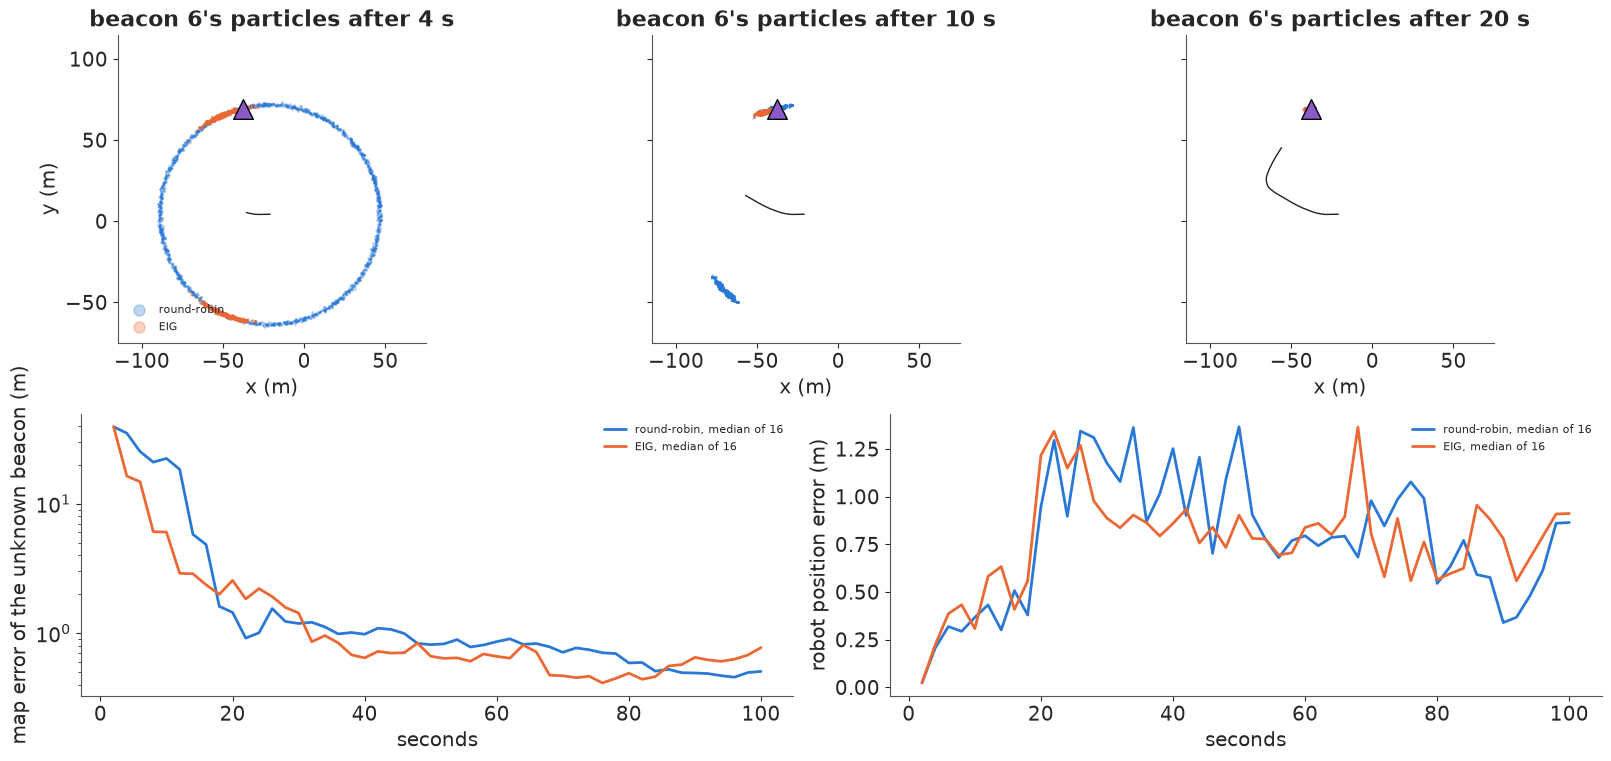

In [22]:
h_ex, s_ex = 3, SLAM_STARTS[1]
snap_w = (1, 4, 9)
_, be_rr, _, sn_rr = slam_replay("round-robin", h_ex, s_ex, SLAM_DUR, 31 * h_ex + int(s_ex), snap_at=snap_w)
_, be_eig, _, sn_eig = slam_replay("EIG", h_ex, s_ex, SLAM_DUR, 31 * h_ex + int(s_ex), snap_at=snap_w)
fig = plt.figure(figsize=(16, 7.5))
sf = fig.subfigures(2, 1, height_ratios=[1.15, 1])
axs = sf[0].subplots(1, 3, sharex=True, sharey=True)
for ax, w in zip(axs, snap_w):
    for sn, c, lab in ((sn_rr, BLUE, "round-robin"), (sn_eig, ORANGE, "EIG")):
        ax.scatter(sn[w][:, 2], sn[w][:, 3], s=1, alpha=0.3, color=c, rasterized=True, label=lab)
    ax.plot(*truth2(np.linspace(s_ex, s_ex + (w + 1) * W, 200)).T, color=INK, lw=1)
    ax.scatter(*BXY2[h_ex], marker="^", s=200, color=BCOL[BEACON_IDS[h_ex]], edgecolor="k", zorder=6)
    ax.set(title=f"beacon {BEACON_IDS[h_ex]}'s particles after {(w + 1) * W:.0f} s", aspect="equal",
           xlim=(-115, 75), ylim=(-75, 115), xlabel="x (m)")
axs[0].set_ylabel("y (m)")
axs[0].legend(fontsize=8, markerscale=8, loc="lower left")
axs = sf[1].subplots(1, 2)
tws = W * np.arange(1, slam["EIG"]["berr"].shape[1] + 1)
for pol, c in (("round-robin", BLUE), ("EIG", ORANGE)):
    axs[0].semilogy(tws, np.nanmedian(slam[pol]["berr"], axis=0), color=c, lw=2, label=f"{pol}, median of 16")
    axs[1].plot(tws, np.median(slam[pol]["rerr"], axis=0), color=c, lw=2, label=f"{pol}, median of 16")
axs[0].set(xlabel="seconds", ylabel="map error of the unknown beacon (m)")
axs[1].set(xlabel="seconds", ylabel="robot position error (m)")
print(f"example run (beacon {BEACON_IDS[h_ex]} hidden, start {s_ex - T0_2:.0f} s): map error at "
      + ", ".join(f"{(w + 1) * W:.0f} s: round-robin {be_rr[w]:.1f} m / EIG {be_eig[w]:.1f} m" for w in snap_w))
axs[0].legend(fontsize=8)
axs[1].legend(fontsize=8);

EIG spends its pings differently: 20 of 50 go to the unknown beacon against round-robin's 13, and
it reaches a rough fix sooner - a median map error of 6 m after 10 s against 22 m, a quarter of
round-robin's. In time the gain is smaller: EIG's median curve first drops below 3 m at 12 s and
round-robin's at 18 s (per run, a median 12 s against 16 s). The example
(beacon 6 hidden, from 105 s into the run) shows how. After 4 s round-robin still has a full ring
for the beacon, because it has had only the first range from it; EIG has spent its next pings
there and is down to two short arcs, the mirror pair either side of the robot's short path. After
10 s round-robin is at that stage - one cluster at the beacon and its mirror image about 110 m away
across the path - while EIG has kept only the right one (7 m off). By 20 s both have it, round-robin
to 0.5 m and EIG to 1.6 m.

After that neither rule is clearly more precise. The median curves in the bottom left cross back
and forth: round-robin is ahead from about 18 to 30 s (1.2 m against 1.4 m at 30 s, with 75% of
runs within 2 m against 56%), EIG from about 32 to 84 s (0.64 against 0.98 m at 40 s, 0.47 against
0.71 m at 70 s), and round-robin again over the last 15 s (0.5 against 0.8 m at 100 s). Over the
windows after 20 s EIG's median is the lower one in 63% of them. With 16 runs per rule these
late differences are about the size of the run-to-run noise. The robot's own error is the same in
the median (0.76 and 0.78 m), with fewer runs straying more than 5 m under EIG (19% against 25%). So
EIG finds an unknown beacon sooner, and the data do not say which rule maps it more precisely.

## 8 · The decision

The engineer's question was which ping schedule to put on the robot, with one ping per two
seconds. The replay answers it on real ranges.

Do not use **nearest**: it never found the robot in three quarters of the episodes. **Round-robin**
is safe once the robot is localised, but with an unknown start it takes a median 16 s to lock and
spends a third of its windows believing mostly the wrong thing. A belief-driven rule cuts the median
lock time to 5-6 s and halves the mean, at the same budget, and after lock it tracks as well as any
other rule, within about a metre. Between the two belief-driven rules, ship the **predicted-range
spread**: it did as well as EIG on every measure here, never failed to lock, and costs one pass over
the particles instead of a nested Monte Carlo sum. Keep **sensor resetting** on whatever the
schedule: it turned 18% of lost episodes into 8% for round-robin. If the robot also has to map a
beacon that was never surveyed, information gain gets the rough fix sooner (a map error of 6 m
against 22 m at 10 s), and after that neither rule mapped the beacon clearly better in 16 runs.

All of this is conditional on the replay. The agent chose which logged range to reveal, never where
to drive, and a robot that could also steer toward informative places could do better still. The
radios on this plaza were clean - the NLOS tail we built a model for was not in the data - and with
heavy-tailed ranges a rule that ignores the noise model, such as spread, could lose its edge to EIG.

In [23]:
print(f"total run time {time.time() - T_START:.0f} s")

total run time 172 s


## Summary

* **The radios read 7% long.** A constant per-beacon bias (2.6-2.9 m) failed its posterior
  predictive check in 12 of 13 distance bins; a shared scale error $\kappa$ = 0.069 with offsets
  under 6 cm passed it, beat the bias model by about 2,600 nats of LOO, and transferred to a run
  recorded with the beacons moved (50% and 90% intervals covered 48.5% and 89.4% of its ranges).
* **The NLOS tail was not there.** An ex-Gaussian mixture for delayed ranges tied the Gaussian model
  on LOO (-0.3 ± 0.5), put its share at 0.06 (89% interval 0-0.21, mostly prior) and sampled worse
  (17 divergences); standardised residuals were Gaussian to ±3.5 sd. Whether the plaza was clean
  or the released log was cleaned, we cannot tell.
* **Calibration does not cover what the calibration run lacks.** Plaza 1's odometry heading was the
  INS heading; Plaza 2's gyro drifted 0.30 deg/s. A per-particle bias state learned 0.25 deg/s from
  ranges alone.
* **A filter can be sure and wrong.** With one ping per 2 s and an unknown start, 18% of round-robin
  episodes never locked; sensor resetting brought that to 8% without changing the typical episode.
* **Choosing the ping cut the time to find the robot by two to three times.** Median lock: 5 s
  (predicted-range spread), 6 s (EIG), 13 s (random), 16 s (round-robin), never in 74% of episodes
  (nearest). At the 81 decisions where the choice mattered, the highest-EIG ping left 0.39 of the mass in the
  wrong place against 0.56 for a random pick (0.17 for the best candidate). After lock all reasonable rules tracked to about 1 m; every range gave 0.3 m.
* **Fusion is the whole difference.** Over 400 s of Plaza 2, 11% of the logged ranges took the
  error from a median 26 m (odometry alone, from the true start) to 0.5 m.
* **Beacon SLAM:** EIG found an unsurveyed beacon sooner (median map error 6 m against 22 m after
  10 s; below 3 m at 12 s against 18 s). After 20 s the two median curves cross back and forth
  between about 0.5 and 1.5 m, and 16 runs per rule cannot separate them.

## Try it yourself

1. **Look two steps ahead.** At the decisions where we tried every counterfactual ping, score every pair of beacons for the
   next two windows by the information the pair gives jointly (simulate the first reply, update a
   copy of the filter, then score the second ping). How often does the best pair start with a beacon
   that is not the one-step EIG choice, and does it shorten the lock times in the table?
2. **Make the noise heavy-tailed.** Replace a random 10% of Plaza 2's ranges with the range plus an
   exponential delay of mean 3 m, refit the NLOS mixture on Plaza 1 with the same contamination, and
   rerun the policy comparison with the mixture likelihood in the filter and in EIG. Does the spread
   rule, which ignores the noise model, fall behind EIG now?
3. **Switch schedules for SLAM.** Run beacon SLAM with a rule that uses EIG until the unknown
   beacon's particle cloud has one cluster (two-means with a small minority mass) and round-robin
   after that. Does it keep EIG's fast first fix and settle any closer to the beacon than either
   rule alone, with more runs than our 16? Try also the harder case of two unknown beacons.